<a href="https://colab.research.google.com/github/fadilaha/Sentiment-Forecast/blob/main/sentiment_forecast%2BExog.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Sentiment forecasting: XGBoost, LightGBM, VAR, ARIMA

Run the cells from top to bottom. Each model has its own cell (steps 6, 7, 8),
so you can run, change or re-run one model without touching the others.

1. Settings: **edit this cell** (column names, timezone)
2. Libraries
3. Load and merge the monthly files
4. Group posts into time bins + overview plot
5. Shared tools (features, walk-forward test, scoring) + the "no change" baseline
6. XGBoost
7. LightGBM
8. VAR
9. Compare all models + save results

## 1. Settings

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
PROJECT_DIR = '/content/drive/MyDrive/sentiment_project'   # folder on the Drive
DATA_FOLDER = 'data_csv'               # subfolder containing the monthly files (csv / xlsx)

TIME_COL  = 'Date'           # timestamp column name in the files
LABEL_COL = 'Sentiment'            # sentiment label column name
INPUT_TZ  = 'Asia/Jakarta'         # timezone of the timestamps in the files
LOCAL_TZ  = 'Asia/Jakarta'         # timezone used for binning (WIB)

TARGET     = 'net'                 # 'net' = (pos - neg)/n, or 'share_pos', 'share_neu', 'share_neg'
FREQS      = ['1h', '6h', '12h', '1D']
HORIZONS_H = [1, 6, 12, 24, 72, 168]   # forecast horizons in hours. Horizons: how far the duration of time that will be predicted.
TEST_START = None                  # e.g. '2026-05-01'; None = first day of the last month
FOLD_DAYS  = 3                     # retrain every 3 days during the test period. Every 3 days, the models are retrained from scratch using all the data available up to that point.
MEDIA_COL   = 'Media'              # column with the platform / source
NEWS_VALUES = ['news']             # media value(s) that count as news (lowercase)
OUT_DIR     = 'results_onlysocial2'       # new folder, so earlier results are not overwritten

import os
os.chdir(PROJECT_DIR)
print('Working in', os.getcwd(), '| files in data:', sorted(os.listdir(DATA_FOLDER)))

Working in /content/drive/MyDrive/sentiment_project | files in data: ['prabowo26_agustus.csv', 'prabowo26_april.csv', 'prabowo26_juli.csv', 'prabowo26_juni.csv', 'prabowo26_mei.csv', 'prabowo26_sept.csv']


## 2. Libraries

In [4]:
!pip install -q xgboost lightgbm holidays
import glob, math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import lightgbm as lgb
warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', message='X does not have valid feature names')
print('xgboost', xgb.__version__, '| lightgbm', lgb.__version__)

xgboost 3.4.1 | lightgbm 4.6.0


## 3. Load and merge the monthly files
Check the printout to ensure that every month present, few (to no) unreadable timestamps, and all label values are recognised.

In [5]:
# LOAD AND MERGE THE MONTHLY CSV FILES
LABEL_MAP = {'positive': 1, 'neutral': 0, 'negative': -1}

# columns to read: the ones the models use now + ones that may become features later
# (Text and Link are skipped: they are large and not used as features)
cols = [TIME_COL, LABEL_COL, 'Media', 'Author', 'Followers', 'Retweeted', 'Favourited']

files = sorted(glob.glob(os.path.join(DATA_FOLDER, '*.csv')))
parts = []
for f in files:
    d = pd.read_csv(f, usecols=cols)                 # read only the needed columns (fast)
    print(f'{os.path.basename(f):40s} {len(d):>10,} rows')
    parts.append(d)
raw = pd.concat(parts, ignore_index=True)

# timestamps -> local time (WIB)
t = pd.to_datetime(raw[TIME_COL], errors='coerce', format='mixed')
if t.dt.tz is None:
    t = t.dt.tz_localize(INPUT_TZ, ambiguous='NaT', nonexistent='NaT')
t = t.dt.tz_convert(LOCAL_TZ)

# labels -> +1 / 0 / -1
lab = raw[LABEL_COL].astype(str).str.strip().str.lower().map(LABEL_MAP)

posts = pd.DataFrame({'time': t, 'label': lab})
posts['media']      = raw['Media'].astype(str).str.strip().str.lower()
posts['author']     = raw['Author'].astype(str)
posts['followers']  = pd.to_numeric(raw['Followers'],  errors='coerce').fillna(0)
posts['retweeted']  = pd.to_numeric(raw['Retweeted'],  errors='coerce').fillna(0)
posts['favourited'] = pd.to_numeric(raw['Favourited'], errors='coerce').fillna(0)
if 'MEDIA_COL' in globals():
    posts['media'] = raw[MEDIA_COL].astype(str).str.strip().str.lower()

print(f'\nTotal rows: {len(raw):,} | unreadable timestamps: {t.isna().sum():,} '
      f'| unrecognised labels: {lab.isna().sum():,}')
if lab.isna().any():
    print('  examples of unrecognised labels:', raw.loc[lab.isna(), LABEL_COL].astype(str).unique()[:10])

posts = posts.dropna(subset=['time', 'label'])
posts['label'] = posts['label'].astype(int)
del raw, parts, t, lab

# quick checks
print(f'Kept {len(posts):,} posts, {posts.time.min()} -> {posts.time.max()}')
print('\nPosts per month:')
print(posts.time.dt.tz_localize(None).dt.to_period('M').value_counts().sort_index().to_string())
print('\nLabels:', posts.label.map({1: 'positive', 0: 'neutral', -1: 'negative'}).value_counts().to_dict())
if 'media' in posts:
    print('\nPosts per media:')
    print(posts.media.value_counts(normalize=True).round(3).to_string())
print('\nPosts by hour of day (should be low at night if the timezone is right):')
print(posts.time.dt.hour.value_counts().sort_index().to_string())

prabowo26_agustus.csv                       330,158 rows
prabowo26_april.csv                         257,472 rows
prabowo26_juli.csv                          323,615 rows
prabowo26_juni.csv                          409,684 rows
prabowo26_mei.csv                           342,500 rows
prabowo26_sept.csv                          331,667 rows

Total rows: 1,995,096 | unreadable timestamps: 0 | unrecognised labels: 0
Kept 1,995,096 posts, 2026-04-01 00:00:00+07:00 -> 2026-09-30 23:59:47+07:00

Posts per month:
time
2026-04    257472
2026-05    342500
2026-06    409684
2026-07    323615
2026-08    330158
2026-09    331667
Freq: M

Labels: {'negative': 946910, 'positive': 827451, 'neutral': 220735}

Posts per media:
media
twitter      0.535
news         0.295
instagram    0.073
youtube      0.065
tiktok       0.011
facebook     0.011
threads      0.009

Posts by hour of day (should be low at night if the timezone is right):
time
0      69756
1      46972
2      35799
3      29525
4      3611

In [6]:
# KEEP ONLY SOCIAL-MEDIA POSTS (exclude news articles)
EXCLUDE_MEDIA = ['news']
posts_all = posts.copy()                       # keep all posts (needed for news features)
posts = posts_all[~posts_all.media.isin(EXCLUDE_MEDIA)].reset_index(drop=True)
print(f'Kept {len(posts):,} of {len(posts_all):,} posts '
      f'({len(posts) / len(posts_all):.1%}) after removing {EXCLUDE_MEDIA}')
print(posts.media.value_counts(normalize=True).round(3).to_string())

Kept 1,407,490 of 1,995,096 posts (70.5%) after removing ['news']
media
twitter      0.759
instagram    0.104
youtube      0.092
tiktok       0.016
facebook     0.016
threads      0.013


## 4. Group posts into time bins

The posts's sentiment is counted (Positive-Negative/N) per hour, per 6 hours, per 12 hours, and per day. The graph shown in this cell is the actual data from January to September. The part that will be predicted and tested is the start of September (marked by dashed line).

  1h:  4,344 bins | posts per bin: median 299, min 0 | empty bins 0.2%
  6h:    724 bins | posts per bin: median 1832, min 214 | empty bins 0.0%
 12h:    362 bins | posts per bin: median 3629, min 1116 | empty bins 0.0%
  1D:    181 bins | posts per bin: median 7258, min 3517 | empty bins 0.0%

Training data: before 2026-09-01 | test: 2026-09-01 onwards


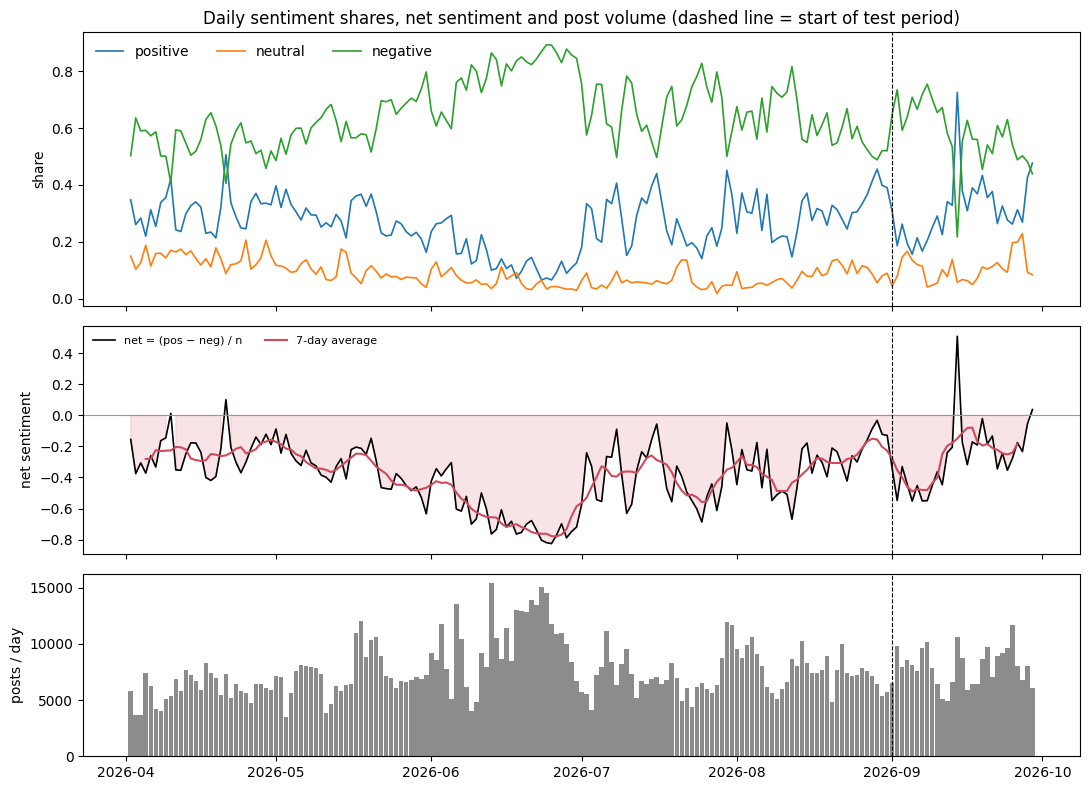

In [7]:
FREQ_HOURS = {'1h': 1, '3h': 3, '6h': 6, '12h': 12, '1d': 24}

def aggregate(posts, freq):
    start = posts.time.min().normalize() + pd.Timedelta(days=1)   # complete days only
    end = posts.time.max().normalize()
    p = posts[(posts.time >= start) & (posts.time < end)]
    counts = p.groupby([pd.Grouper(key='time', freq=freq), 'label']).size().unstack(fill_value=0)
    idx = pd.date_range(start, end, freq=freq, inclusive='left')
    counts = counts.reindex(idx, fill_value=0)
    for k in (-1, 0, 1):
        if k not in counts.columns:
            counts[k] = 0
    a = pd.DataFrame(index=idx)
    a['n_neg'], a['n_neu'], a['n_pos'] = counts[-1], counts[0], counts[1]
    a['n'] = a[['n_neg', 'n_neu', 'n_pos']].sum(axis=1)
    nz = a['n'].replace(0, np.nan)
    a['share_pos'], a['share_neu'], a['share_neg'] = a.n_pos / nz, a.n_neu / nz, a.n_neg / nz
    a['net'] = (a.n_pos - a.n_neg) / nz
    a['is_empty'] = (a.n == 0).astype(int)
    c = ['share_pos', 'share_neu', 'share_neg', 'net']
    # Carry forward the latest observed sentiment for empty bins.
    # Remove leading bins that have no previous sentiment observation.
    a[c] = a[c].ffill()
    a = a.dropna(subset=c)
    a['logn'] = np.log1p(a.n)
    return a

os.makedirs(OUT_DIR, exist_ok=True)
AGGS = {}
for fq in FREQS:
    AGGS[fq] = aggregate(posts, fq)
    AGGS[fq].to_csv(f'{OUT_DIR}/aggregated_{fq}.csv', index_label='bin_start')
    a = AGGS[fq]
    print(f'{fq:>4}: {len(a):6,} bins | posts per bin: median {a.n.median():.0f}, '
          f'min {a.n.min():.0f} | empty bins {a.is_empty.mean():.1%}')

if TEST_START:
    TEST_START_TS = pd.Timestamp(TEST_START, tz=LOCAL_TZ)
else:
    last = posts.time.max()
    TEST_START_TS = pd.Timestamp(year=last.year, month=last.month, day=1, tz=LOCAL_TZ)
print(f'\nTraining data: before {TEST_START_TS.date()} | test: {TEST_START_TS.date()} onwards')

d = aggregate(posts, '1D')
fig, ax = plt.subplots(3, 1, figsize=(11, 8), sharex=True,
                       gridspec_kw={'height_ratios': [1.2, 1, 0.8]})
for c, l in (('share_pos', 'positive'), ('share_neu', 'neutral'), ('share_neg', 'negative')):
    ax[0].plot(d.index, d[c], label=l, lw=1.2)
ax[0].set_ylabel('share'); ax[0].legend(frameon=False, ncol=3)
ax[0].set_title('Daily sentiment shares, net sentiment and post volume (dashed line = start of test period)')
ax[1].plot(d.index, d.net, color='k', lw=1.2, label='net = (pos − neg) / n')
ax[1].plot(d.index, d.net.rolling(7, center=True).mean(), color='#d1495b', lw=1.5,
           label='7-day average')
ax[1].fill_between(d.index, 0, d.net, where=d.net >= 0, color='#2a6fbb', alpha=0.15)
ax[1].fill_between(d.index, 0, d.net, where=d.net < 0, color='#d1495b', alpha=0.15)
ax[1].axhline(0, color='0.6', lw=0.8)
ax[1].set_ylabel('net sentiment'); ax[1].legend(frameon=False, ncol=2, fontsize=8, loc='upper left')
ax[2].bar(d.index, d.n, width=0.9, color='0.55'); ax[2].set_ylabel('posts / day')
for a in ax:
    a.axvline(TEST_START_TS, color='k', ls='--', lw=0.8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/series_daily.png', dpi=140); plt.show()

In [13]:
import numpy as np, pandas as pd

fq, bh = '1h', 1                          # ganti ke '1D', 24 untuk cek bin harian
TRAIN_END_TS = pd.Timestamp('2026-08-01', tz='Asia/Jakarta')
p = posts[posts.time < TRAIN_END_TS].copy()

p['eng'] = p['retweeted'].fillna(0) + p['favourited'].fillna(0)
p['w_lab'] = p['label'] * p['eng']
thr = p['Followers'].quantile(0.99)       # batas akun besar (top 1%)
big = p[p['Followers'] >= thr]

g = p.groupby(pd.Grouper(key='time', freq=fq))
feat = pd.DataFrame({
    'y':       g.label.mean(),                               # net sentiment
    'log_eng': np.log1p(g.eng.sum()),
    'eng_net': g.w_lab.sum() / g.eng.sum().replace(0, np.nan),
    'big_net': big.groupby(pd.Grouper(key='time', freq=fq)).label.mean(),
}).ffill()

out = {}
for col in ['log_eng', 'eng_net', 'big_net']:
    row = {}
    for h in [1, 6, 24, 72, 168]:
        k = h // bh
        if k == 0: continue
        d = pd.DataFrame({'t': feat.y.shift(-k) - feat.y, 'y0': feat.y,
                          'x': feat[col].shift(24 // bh if bh < 24 else 1)}).dropna()  # jeda 1 hari
        rt = d.t - np.polyval(np.polyfit(d.y0, d.t, 1), d.y0)
        rx = d.x - np.polyval(np.polyfit(d.y0, d.x, 1), d.y0)
        row[f'h={h}'] = np.corrcoef(rt, rx)[0, 1]
    out[col] = row
display(pd.DataFrame(out).T.round(3))

KeyError: 'Retweeted'

## **Preparation: features engineering, test weeks and comparison to naive forecast**
**Nothing is predicted in this cell.** It prepares everything the model cells (6, 7, 8) need. It has four jobs.

### Job 1: build the features (the models' inputs)
A model can't read a raw sentiment line. It needs a **table**: one row per moment in time, one column per
piece of information that is already known at that moment. Example row for 13 September 20:00 (row are the time, columns are features):

| Feature | Meaning |
|---|---|
| `y_lag0` | net sentiment now |
| `y_lag1`, `y_lag2` | net sentiment 1 and 2 bins ago |
| `y_mean24` | average net over the last 24 bins |
| `y_std_day` | how much net jumped around during the last day (volatility) |
| `y_dev_week` | how far net is from its 7-day average |
| `share_pos`, `share_neu`, `share_neg` | the shares now (except the one being forecast) |
| `logn` | how many posts there are now (log scale) |
| `logn_surge` | is volume unusually high vs the last 7 days? (**event signal**) |
| `hour_sin/cos`, `dow_sin/cos` | time of day and day of week (as a circle, so 23:00 is close to 00:00) |

XGBoost and LightGBM learn from this table. VAR (cell 8) uses the raw series directly.

### Job 2: set up the test weeks (folds)
The test period (from `TEST_START`) is cut into blocks of `FOLD_DAYS` (7) days. Before each block, the models are retrained on all data before that block, so September data is added as it "arrives":

| Fold | Trained on | Forecasts for |
|---|---|---|
| 1 | 1 Jan – 31 Aug | 1 – 7 Sep |
| 2 | 1 Jan – 7 Sep | 8 – 14 Sep |
| … | … | … |

A model is never allowed to see the value it is forecasting (no "future leakage").

### Job 3: build the "no change" yardstick
For every moment in the test period it records the simplest possible forecast: **the future = the value now.** It is also called the *persistence* or *naive* forecast.
**Why is it needed?** An error number alone means nothing. If XGBoost's average error (MAE) is 0.08, is that good?
We can't tell without something to compare it with. The fairest comparison is the simplest thing to do without a model, **assume nothing changes**. Sentiment usually changes slowly, so "same as now" is often close. That makes it an honest benchmark.

### Job 4: define helper tools used later
* `run_tree_model`: trains XGBoost / LightGBM fold by fold (used in cells 6 and 7)
* `score`: compares a model with "no change"
* `show`: prints the skill table

### How to read **skill** (comparison of model result and 'no change' assumption)
**skill = 1 − (model error ÷ "no change" error)**

| Skill | Meaning |
|---|---|
| 0.30 | the model's error is 30 % smaller than "no change", so it's useful |
| 0 | no better than copying the current value |
| below 0 | **worse** than copying the current value, so the model hurts |

Example from this data: XGBoost with daily bins, 24 h ahead, had skill −0.03, so it was worse than simply copying today's value. Without the yardstick that would have looked like a normal error number.

In [49]:
# FEATURE 1: LAG FEATURES
# Capture past sentiment values at selected time intervals.
# These features help the model recognize temporal dependencies
# without requiring the entire time series as a sequence.

def build_lag_features(agg, hours):

    # Number of time bins in one day and one week
    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    y = agg[TARGET]
    f = pd.DataFrame(index=agg.index)

    # Selected historical positions:
    # Current value, 1 and 2 bins ago, approximately 1 day ago,
    # 2 days ago, and 1 week ago.
    lag_steps = sorted({
        0, 1, 2,
        bins_per_day,
        2 * bins_per_day,
        bins_per_week
    })
    for lag in lag_steps:
        f[f'y_lag{lag}'] = y.shift(lag)

    return f

In [50]:
# FEATURE 2: ROLLING MEAN FEATURES
# Calculate the average sentiment over recent time windows.
# These features help the model identify short-term and
# long-term sentiment trends while reducing short-term fluctuations.

def build_rolling_mean_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    y = agg[TARGET]
    f = pd.DataFrame(index=agg.index)

    # Rolling windows: last 3 bins, 1 day, and 1 week
    windows = sorted({3, bins_per_day, bins_per_week})

    for window in windows:
        if window >= 2:
            f[f'y_mean{window}'] = y.rolling(window).mean()

    return f

In [51]:
# FEATURE 3: SENTIMENT VOLATILITY AND CHANGE FEATURES
# Capture how much sentiment fluctuates, how fast it changes,
# and how far the current sentiment deviates from its recent average.

def build_sentiment_dynamics_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    y = agg[TARGET]
    f = pd.DataFrame(index=agg.index)

    # 1. Daily volatility (standard deviation)
    # At least 3 bins are used to calculate volatility.
    f['y_std_recent'] = y.rolling(max(bins_per_day, 3)).std()

    # 2. First difference: change from the previous time bin
    f['y_diff1'] = y.diff()

    # 3. Deviation from the rolling weekly average
    f['y_dev_week'] = y - y.rolling(bins_per_week).mean()

    return f

In [52]:
# FEATURE 4: SENTIMENT COMPOSITION FEATURES
# Include the current shares of positive, neutral, and negative sentiment.
# This provides additional information about sentiment composition
# beyond the main target variable.

def build_sentiment_share_features(agg):

    f = pd.DataFrame(index=agg.index)

    for col in ('share_pos', 'share_neu', 'share_neg'):
        if col != TARGET:
            f[col] = agg[col]

    return f

In [53]:
# FEATURE 5: POST VOLUME FEATURES
# Capture the current discussion volume, unusual increases in activity,
# and changes in the number of posts over time.

def build_volume_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    logn = agg['logn']
    f = pd.DataFrame(index=agg.index)

    # Current post volume (log-transformed)
    f['logn'] = logn

    # Difference between current volume and its weekly average.
    # Positive values indicate higher activity than the recent baseline.
    f['logn_surge'] = logn - logn.rolling(bins_per_week).mean()

    # Change in post volume from the previous time bin
    f['logn_diff1'] = logn.diff()

    # Indicator for time bins with no posts
    f['is_empty'] = agg['is_empty']

    return f

In [54]:
# FEATURE 6: CALENDAR FEATURES (FOURIER TERMS)
# Represent time as cyclical variables using sine and cosine transformations.
# This allows the model to recognize periodic patterns, such as daily
# and weekly sentiment differences.

def build_calendar_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    f = pd.DataFrame(index=agg.index)

    # Hour of day: only applicable to sub-daily time bins
    if bins_per_day > 1:

        hour = agg.index.hour + agg.index.minute / 60

        f['hour_sin'] = np.sin(2 * np.pi * hour / 24)
        f['hour_cos'] = np.cos(2 * np.pi * hour / 24)

    # Day of week: Monday = 0, Sunday = 6
    day_of_week = agg.index.dayofweek

    f['dow_sin'] = np.sin(2 * np.pi * day_of_week / 7)
    f['dow_cos'] = np.cos(2 * np.pi * day_of_week / 7)

    return f

In [55]:
# FEATURE 7: EXOGENOUS FEATURES (from outside the sentiment series)
# 1. News coverage    : number of news articles per bin (media agenda / events)
# 2. Platform mix     : share of posts from each platform (Twitter, YouTube, ...)
# 3. Calendar flags   : weekend, active hours (day/night), national holiday
# News and platform values are only known once a bin has happened, so they are used
# as values "up to now" (current bin and earlier) -> no future leakage.
# Calendar flags are known in advance.

# --- 1. add media counts per bin to every aggregated table -----------------------
def add_media_counts(agg, freq):
    c = (posts_all.groupby([pd.Grouper(key='time', freq=freq), 'media'])
              .size().unstack(fill_value=0))
    c = c.reindex(agg.index, fill_value=0)
    c.columns = ['m_' + str(col).replace(' ', '_') for col in c.columns]
    return agg.drop(columns=[x for x in agg.columns if x.startswith('m_')]).join(c)

for fq in AGGS:
    AGGS[fq] = add_media_counts(AGGS[fq], fq)

# media values counted as "news", and platforms with at least 1% of all posts
NEWS_COLS = ['m_' + v.replace(' ', '_') for v in NEWS_VALUES]
media_share = posts['media'].value_counts(normalize=True)
PLATFORM_COLS = ['m_' + str(v).replace(' ', '_') for v, s in media_share.items()
                 if s >= 0.01 and v not in NEWS_VALUES]
print('News columns    :', [c for c in NEWS_COLS if c in AGGS[FREQS[0]].columns])
print('Platform columns:', PLATFORM_COLS)

# --- national holidays (Indonesia) -------------------------------------------------
try:
    import holidays
    years = sorted(posts.time.dt.year.unique())
    HOLIDAY_DATES = pd.DatetimeIndex(sorted(holidays.Indonesia(years=years).keys()))
    print(f'{len(HOLIDAY_DATES)} Indonesian public holidays loaded')
except Exception as e:
    HOLIDAY_DATES = pd.DatetimeIndex([])
    print('holidays package not available -> holiday flag set to 0 (pip install holidays)')


# --- 2. the feature function -------------------------------------------------------
def build_exogenous_features(agg, hours):

    bins_per_day = max(1, 24 // hours)
    bins_per_week = 7 * bins_per_day

    f = pd.DataFrame(index=agg.index)
    n = agg['n'].clip(lower=1)

    # News coverage
    news_cols = [c for c in NEWS_COLS if c in agg.columns]
    news = agg[news_cols].sum(axis=1) if news_cols else pd.Series(0.0, index=agg.index)
    news_log = np.log1p(news)
    f['news_logn']  = news_log                                          # news volume now
    f['news_surge'] = news_log - news_log.rolling(bins_per_week).mean() # vs its 7-day average
    f['news_share'] = news / (n + news)                                 # news as share of all posts

    # Platform mix
    for col in PLATFORM_COLS:
        if col in agg.columns:
            f['plat_' + col[2:]] = agg[col] / n

    # Calendar flags (known in advance)
    f['is_weekend'] = (agg.index.dayofweek >= 5).astype(int)
    if bins_per_day > 1:                                   # day/night only for sub-daily bins
        f['is_active_hours'] = ((agg.index.hour >= 6) & (agg.index.hour < 22)).astype(int)
    days = agg.index.tz_localize(None).normalize()
    f['is_holiday'] = days.isin(HOLIDAY_DATES).astype(int)

    return f

News columns    : ['m_news']
Platform columns: ['m_twitter', 'm_instagram', 'm_youtube', 'm_facebook', 'm_threads', 'm_tiktok']
17 Indonesian public holidays loaded


In [56]:
# FEATURE 8: COMBINE ALL FEATURES
# Combine all feature groups into a single DataFrame.
# Each row represents one time bin, while each column represents
# one feature describing the information available at that time.

def build_features(agg, hours):

    features = [
        build_lag_features(agg, hours),
        build_rolling_mean_features(agg, hours),
        build_sentiment_dynamics_features(agg, hours),
        #build_sentiment_share_features(agg),
        #build_volume_features(agg, hours),
        build_calendar_features(agg, hours),
        build_exogenous_features(agg, hours)      # <-- new
    ]

    f = pd.concat(features, axis=1)
    return f

The output of feature engineering is a DataFrame in which each row represents one time bin and each column represents an engineered feature. Each row therefore contains information available at a particular timestamp, including historical sentiment, recent trends, volatility, sentiment composition, post volume, and temporal patterns. The DataFrame is subsequently converted into a NumPy array to serve as the input feature matrix for machine learning models.

In [57]:
# INSPECT FEATURE ENGINEERING OUTPUT
# Ensure the produced features are matched with our expectation
# Example using 6-hour aggregated data
example_agg = AGGS['6h']

feats = build_features(
    example_agg,
    FREQ_HOURS['6h']
)

print("Feature matrix shape:", feats.shape)
print("\nFeature names:")
print(feats.columns.tolist())

print("\nFeature matrix preview:")
display(feats.head())

Feature matrix shape: (480, 28)

Feature names:
['y_lag0', 'y_lag1', 'y_lag2', 'y_lag4', 'y_lag8', 'y_lag28', 'y_mean3', 'y_mean4', 'y_mean28', 'y_std_recent', 'y_diff1', 'y_dev_week', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'news_logn', 'news_surge', 'news_share', 'plat_twitter', 'plat_instagram', 'plat_youtube', 'plat_facebook', 'plat_threads', 'plat_tiktok', 'is_weekend', 'is_active_hours', 'is_holiday']

Feature matrix preview:


,y_lag0,y_lag1,y_lag2,y_lag4,y_lag8,y_lag28,y_mean3,y_mean4,y_mean28,y_std_recent,...,news_share,plat_twitter,plat_instagram,plat_youtube,plat_facebook,plat_threads,plat_tiktok,is_weekend,is_active_hours,is_holiday
2026-06-02 00:00:00+07:00,-0.652911,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.271605,0.883567,0.043478,0.047163,0.005895,0.005158,0.014738,0,0,0
2026-06-02 06:00:00+07:00,-0.392512,-0.652911,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.372252,0.785829,0.079308,0.071256,0.008454,0.008052,0.047101,0,1,0
2026-06-02 12:00:00+07:00,-0.295067,-0.392512,-0.652911,NaN,NaN,NaN,-0.446830,NaN,NaN,NaN,...,0.528990,0.739972,0.083449,0.117105,0.010604,0.003688,0.045182,0,1,0
2026-06-02 18:00:00+07:00,-0.174884,-0.295067,-0.392512,NaN,NaN,NaN,-0.287488,-0.378844,NaN,0.203238,...,0.503823,0.681048,0.076271,0.138290,0.029661,0.007704,0.067026,0,1,0
2026-06-03 00:00:00+07:00,-0.660748,-0.174884,-0.295067,-0.652911,NaN,NaN,-0.376900,-0.380803,NaN,0.206768,...,0.372713,0.883957,0.036145,0.045656,0.003805,0.005073,0.025365,0,0,0


In [58]:
# DATASET PREPARATION
# Build the feature matrix, target series, sample weights,
# and forecasting horizons for each time frequency.
# All datasets are stored in DATA[freq], e.g. DATA['6h'].

DATA = {}

for fq, agg in AGGS.items():

    hours = FREQ_HOURS[fq.lower()]

    # Build the feature DataFrame
    feats = build_features(agg, hours)

    # Convert features into a numerical matrix for model input
    X = feats.to_numpy(dtype=float)

    # Target variable to be forecast
    y = agg[TARGET].to_numpy(dtype=float)

    # Store timestamps
    times = agg.index

    # Exclude rows containing missing feature values
    # Missing values mainly occur at the beginning of the series
    # because rolling windows and lag features require historical data.
    valid = ~np.isnan(X).any(axis=1)

    # Assign sample weights based on post volume.
    # Bins with more posts receive higher training weights.
    w = np.sqrt(np.clip(agg.n.to_numpy(dtype=float), 1, None))
    w /= w.mean()

    # Convert forecasting horizons from hours into time-bin steps.
    # Only horizons that match the selected bin frequency are retained.
    steps = [
        h // hours
        for h in HORIZONS_H
        if h % hours == 0 and h >= hours
    ]

    # Store all information for this frequency
    DATA[fq] = dict(
        agg=agg,
        hours=hours,
        X=X,
        features=feats,
        feature_names=list(feats.columns),
        y=y,
        w=w,
        valid=valid,
        times=times,
        T=len(agg),
        steps=steps
    )

    print(
        f'{fq:>4}: {X.shape[0]} time bins, '
        f'{X.shape[1]} features, '
        f'horizons (steps): {steps}'
    )

  1h: 2880 time bins, 28 features, horizons (steps): [1, 6, 12, 24, 72, 168]
  6h: 480 time bins, 28 features, horizons (steps): [1, 2, 4, 12, 28]
 12h: 240 time bins, 27 features, horizons (steps): [1, 2, 6, 14]
  1D: 120 time bins, 22 features, horizons (steps): [1, 3, 7]


In [59]:
# TEMPORAL TEST SPLITTING
# Divide the test period into consecutive time blocks (folds).
# Each fold represents a period to be evaluated.
# As the test period moves forward, additional historical data
# becomes available for model retraining.

for fq, D in DATA.items():

    times = D['times']
    valid = D['valid']
    T = D['T']

    folds = []

    for fold_start in pd.date_range(
        TEST_START_TS,
        times[-1],
        freq=f'{FOLD_DAYS}D'
    ):

        # Identify valid forecasting origins within the current test fold
        in_fold = (
            (times >= fold_start) &
            (times < fold_start + pd.Timedelta(days=FOLD_DAYS))
        )

        test_origins = np.where(in_fold & valid)[0]

        # First time bin that cannot be used as a training target
        train_end = int(np.searchsorted(times, fold_start))

        if len(test_origins) > 0:
            folds.append(
                (fold_start, test_origins, train_end)
            )

    D['folds'] = folds

    print(f'{fq:>4}: {len(folds)} test folds created')

  1h: 10 test folds created
  6h: 10 test folds created
 12h: 10 test folds created
  1D: 10 test folds created


In [60]:
# STATIONARITY TEST (ADF)
from statsmodels.tsa.stattools import adfuller

def adf_test(series):
    series = pd.Series(series).dropna()

    result = adfuller(series, autolag='AIC')

    return {
        'ADF statistic': result[0],
        'p-value': result[1],
        'stationary': result[1] < 0.05
    }

ADF_ROWS = []

for fq, D in DATA.items():

    # Use only the first fold's training data
    _, _, train_end = D['folds'][0]

    agg = D['agg']

    # Variables used by VAR
    var_series = {
        'net': agg['net'].iloc[:train_end],
        'share_neu': agg['share_neu'].iloc[:train_end],
        'logn': np.log1p(agg['n'].iloc[:train_end])
    }

    # Target used by ARIMA
    arima_series = {
        'ARIMA target': D['y'][:train_end]
    }

    for name, series in {**var_series, **arima_series}.items():

        result = adf_test(series)

        ADF_ROWS.append({
            'frequency': fq,
            'variable': name,
            **result
        })

ADF_RESULTS = pd.DataFrame(ADF_ROWS)

display(ADF_RESULTS.round(4))

,frequency,variable,ADF statistic,p-value,stationary
0,1h,net,-3.2616,0.0167,True
1,1h,share_neu,-5.6685,0.0000,True
2,1h,logn,-5.4203,0.0000,True
3,1h,ARIMA target,-3.2616,0.0167,True
4,6h,net,-1.8593,0.3515,False
5,6h,share_neu,-3.1992,0.0200,True
6,6h,logn,-2.7532,0.0653,False
7,6h,ARIMA target,-1.8593,0.3515,False
8,12h,net,-1.5898,0.4887,False
9,12h,share_neu,-4.8973,0.0000,True


In [61]:
# PERSISTENCE BASELINE
# Create a naive forecasting baseline.
# Assumption: future sentiment will remain equal to the current sentiment.
# Forecast: y(t + h) = y(t)

def to_frame(name, fq, s, origins, y_true, y_pred):

    D = DATA[fq]

    return pd.DataFrame(dict(
        model=name,
        freq=fq,
        horizon_h=s * D['hours'],
        origin=origins,
        origin_time=D['times'][origins],
        y_true=y_true,
        y_pred=y_pred
    ))


rows = []

for fq, D in DATA.items():

    for fold_start, test_origins, train_end in D['folds']:

        for s in D['steps']:

            # Exclude forecasts that extend beyond the available data
            origins = test_origins[
                test_origins + s < D['T']
            ]

            # Actual future sentiment
            y_true = D['y'][origins + s]

            # Persistence prediction: future sentiment = current sentiment
            y_pred = D['y'][origins]

            rows.append(
                to_frame(
                    'persistence',
                    fq,
                    s,
                    origins,
                    y_true,
                    y_pred
                )
            )


# Store all baseline forecasts in PRED
PRED = {
    'persistence': pd.concat(rows, ignore_index=True)
}

print(
    'Persistence baseline created:',
    len(PRED['persistence']),
    'forecast points'
)

Persistence baseline created: 4711 forecast points


In [62]:
# MODEL EVALUATION
# Calculate forecasting errors and skill scores.
# Each model is compared against the persistence baseline
# using exactly the same forecasting points.

def score(name):

    # Match model predictions with persistence predictions
    P = PRED[name].merge(
        PRED['persistence'][
            ['freq', 'horizon_h', 'origin', 'y_pred']
        ],
        on=['freq', 'horizon_h', 'origin'],
        suffixes=('', '_pers')
    )

    # Absolute forecasting errors
    P['err'] = (P.y_pred - P.y_true).abs()

    # Absolute errors from persistence baseline
    P['err_pers'] = (P.y_pred_pers - P.y_true).abs()

    # Squared errors
    P['sq'] = (P.y_pred - P.y_true) ** 2

    # Calculate metrics for each frequency and horizon
    S = P.groupby(
        ['freq', 'horizon_h'],
        sort=False
    ).agg(
        n=('err', 'size'),
        MAE=('err', 'mean'),
        MSE=('sq', 'mean'),
        MAE_pers=('err_pers', 'mean')
    )

    # Root Mean Squared Error
    S['RMSE'] = np.sqrt(S.pop('MSE'))

    # Forecasting skill relative to persistence
    S['skill'] = 1 - S.MAE / S.MAE_pers

    S.insert(0, 'model', name)

    return S.reset_index()

In [63]:
# DISPLAY MODEL PERFORMANCE
# Show forecasting skill for each time frequency and horizon.
# Positive skill indicates better performance than persistence.

def show(name):

    S = score(name)

    print(f'\n{name}: Skill vs Persistence Baseline')

    print(
        S.pivot(
            index='horizon_h',
            columns='freq',
            values='skill'
        )[list(DATA)].round(3).to_string()
    )

    return S

In [64]:
# TREE-BASED MODEL TRAINING
# Train and evaluate XGBoost or LightGBM models using expanding-window folds.
# A separate model is trained for each:
# - Time frequency
# - Forecasting horizon
# - Test fold
# The model learns future sentiment changes rather than sentiment levels.

def run_tree_model(name, make_model):

    rows = []
    last_models = {}

    for fq, D in DATA.items():

        t0 = time.time()

        X = D['X']
        y = D['y']
        w = D['w']
        T = D['T']

        for fold_id, (fold_start, test_origins, train_end) in enumerate(D['folds']):

            for s in D['steps']:

                # Testing origins: ensure future targets are within the dataset
                origins = test_origins[
                    test_origins + s < T
                ]

                # Training rows:
                # Their future target (row + horizon) must occur before
                # the current test fold to prevent future data leakage.
                tr = np.where(
                    D['valid'] &
                    (np.arange(T) + s < train_end)
                )[0]

                # Skip folds with insufficient training or testing data
                if len(origins) == 0 or len(tr) < 50:
                    continue

                # Initialize a new model
                m = make_model()

                # Training target: sentiment change over the selected horizon
                delta_y = y[tr + s] - y[tr]

                m.fit(
                    X[tr],
                    delta_y,
                    sample_weight=w[tr + s]
                )

                # Predict future sentiment change
                predicted_change = m.predict(X[origins])

                # Convert predicted changes into future sentiment levels
                y_hat = y[origins] + predicted_change

                # Store forecasts
                rows.append(
                    to_frame(
                        name,
                        fq,
                        s,
                        origins,
                        y[origins + s],
                        y_hat
                    )
                )

                # Keep the latest model for feature importance analysis
                last_models[(fq, s * D['hours'], fold_id)] = m

        print(
            f'{name} {fq:>4} completed '
            f'in {time.time() - t0:.0f}s'
        )

    if not rows:
        raise ValueError(
            f'No training results generated for {name}. '
            'Check the folds and training data.'
        )

    return pd.concat(rows, ignore_index=True), last_models

## **XGBoost**
Gradient-boosted trees on the features from step 5. Combines weak learner trees that is retrained (or fixed) based on the previous result's residual to form a more accurate model.  
This models make a forecast by asking a long series of simple yes/no questions about the data, such as “Is posting unusually busy today?” or “Was sentiment negative yesterday?” Each chain of questions is called a “tree”. It build hundreds of these trees, each new one fixing the mistakes of the ones before, and add their answers together.
XGBoost asks its questions evenly. It asks one round of questions about every group in the data before going any deeper.  
Settings can be changed in `make_xgb`.

In [65]:
def make_xgb():
    return xgb.XGBRegressor(n_estimators=100, learning_rate=0.01, max_depth=3,
                            subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                            reg_lambda=1.0, n_jobs=-1, verbosity=0, random_state=0)

PRED['xgboost'], XGB_MODELS = run_tree_model('xgboost', make_xgb)
show('xgboost')

xgboost   1h completed in 32s
xgboost   6h completed in 4s
xgboost  12h completed in 6s
xgboost   1D completed in 1s

xgboost: Skill vs Persistence Baseline
freq          1h     6h    12h     1D
horizon_h                            
1          0.083    NaN    NaN    NaN
6          0.142  0.191    NaN    NaN
12         0.161  0.205  0.087    NaN
24         0.132  0.062  0.061 -0.017
72         0.153  0.141  0.075  0.098
168        0.177  0.112  0.053 -0.026


,freq,horizon_h,model,n,MAE,MAE_pers,RMSE,skill
0,1h,1,xgboost,695,0.147116,0.160395,0.188841,0.082790
1,1h,6,xgboost,690,0.189775,0.221059,0.243123,0.141519
2,1h,12,xgboost,684,0.200134,0.238645,0.258266,0.161374
3,1h,24,xgboost,672,0.216510,0.249340,0.286721,0.131666
4,1h,72,xgboost,624,0.223223,0.263442,0.298730,0.152666
5,1h,168,xgboost,528,0.247978,0.301358,0.332778,0.177130
6,6h,6,xgboost,115,0.113873,0.140837,0.160064,0.191454
7,6h,12,xgboost,114,0.137591,0.173080,0.194942,0.205044
8,6h,24,xgboost,112,0.187526,0.199815,0.261067,0.061503
9,6h,72,xgboost,104,0.191218,0.222542,0.276078,0.140752


## **LightGBM**
It also has similar mechanism like XGboost. However while XGboost questions on each group evenly, LightGBM asks its questions where they help most. It keeps digging into whichever group is still predicted worst and leaves the rest. It’s faster and sharper, but with little data it can focus too much on details that don’t really matter.  


Same features and setup as XGBoost, different boosting library.

In [66]:
def make_lgb():
    return lgb.LGBMRegressor(n_estimators=500, learning_rate=0.01, num_leaves=15,
                             min_child_samples=20, subsample=0.8, subsample_freq=1,
                             colsample_bytree=0.8, reg_lambda=1.0, verbose=-1, random_state=0)

PRED['lightgbm'], LGB_MODELS = run_tree_model('lightgbm', make_lgb)
show('lightgbm')

lightgbm   1h completed in 44s
lightgbm   6h completed in 11s
lightgbm  12h completed in 4s
lightgbm   1D completed in 1s

lightgbm: Skill vs Persistence Baseline
freq          1h     6h    12h     1D
horizon_h                            
1          0.083    NaN    NaN    NaN
6          0.165  0.127    NaN    NaN
12         0.152  0.107 -0.005    NaN
24         0.082  0.021  0.052 -0.064
72         0.094  0.121 -0.035 -0.048
168        0.113  0.014 -0.119 -0.086


,freq,horizon_h,model,n,MAE,MAE_pers,RMSE,skill
0,1h,1,lightgbm,695,0.147052,0.160395,0.189848,0.083187
1,1h,6,lightgbm,690,0.184618,0.221059,0.244250,0.164847
2,1h,12,lightgbm,684,0.202311,0.238645,0.268811,0.152249
3,1h,24,lightgbm,672,0.228908,0.249340,0.295676,0.081944
4,1h,72,lightgbm,624,0.238620,0.263442,0.310193,0.094222
5,1h,168,lightgbm,528,0.267448,0.301358,0.339663,0.112522
6,6h,6,lightgbm,115,0.122989,0.140837,0.170593,0.126730
7,6h,12,lightgbm,114,0.154613,0.173080,0.214156,0.106696
8,6h,24,lightgbm,112,0.195522,0.199815,0.274790,0.021489
9,6h,72,lightgbm,104,0.195685,0.222542,0.274433,0.120680


## **VAR**
VAR (Vector Autoregression) forecasts using a simple formula. The next value is a weighted mix of recent past values. It follows three series together (net sentiment, neutral share and post volume), so it can capture how they influence each other, for example a sudden burst of posts pushing sentiment down the next day. The regular daily and weekly rhythm is included as a fixed background pattern. To forecast further ahead, it predicts one step at a time and builds on its own predictions.

Its limitation is that it only captures straight-line relationships, so it can miss more complex patterns that tree models may find.

In [67]:
# DEFINE VARIABLES INCLUDED IN THE VAR MODEL
VAR_VARS = ['net', 'share_neu', 'logn']

# Maximum lag order tested for each time frequency
P_MAX = {
    1: 24,
    3: 16,
    6: 8,
    12: 6,
    24: 7
}

# Generate Fourier terms to represent daily and weekly seasonality
def fourier_terms(index, hours):

    t_h = np.asarray(
        (index - index[0]) / pd.Timedelta(hours=1),
        float
    )

    cols = []

    # Daily seasonality
    if hours < 24:
        for k in (1, 2, 3):
            cols += [
                np.sin(2 * np.pi * k * t_h / 24),
                np.cos(2 * np.pi * k * t_h / 24)
            ]

    # Weekly seasonality
    for k in (1, 2):
        cols += [
            np.sin(2 * np.pi * k * t_h / 168),
            np.cos(2 * np.pi * k * t_h / 168)
        ]

    return np.column_stack(cols)

In [68]:
# DEFINE VAR TRAINING FUNCTIONS
# Construct the VAR regression matrix using historical lags
def var_design(Z, E, p, rows):

    return np.hstack(
        [np.ones((len(rows), 1)), E[rows]]
        + [Z[rows - L] for L in range(1, p + 1)]
    )


# Estimate VAR coefficients and select lag order using BIC
def fit_var(Z, E, train_end, p_max, ridge=1e-3):

    rows = np.arange(p_max, train_end)

    Y = Z[rows]
    best = None

    for p in range(1, p_max + 1):

        X = var_design(Z, E, p, rows)

        # Estimate coefficients using ridge-regularized least squares
        B = np.linalg.solve(
            X.T @ X + ridge * np.eye(X.shape[1]),
            X.T @ Y
        )

        # Calculate residuals
        R = Y - X @ B

        # Calculate BIC
        covariance = R.T @ R / len(rows)

        sign, logdet = np.linalg.slogdet(
            covariance + 1e-8 * np.eye(Y.shape[1])
        )

        bic = (
            logdet
            + B.size * np.log(len(rows)) / len(rows)
        )

        # Keep the model with the lowest BIC
        if best is None or bic < best[0]:
            best = (bic, p, B)

    return best[1], best[2], best[0]

In [69]:
# DEFINE VAR FORECASTING FUNCTIONS
# Generate multi-step-ahead VAR forecasts
def forecast_var(Z, E, p, B, origins, max_steps):

    n = len(origins)
    k = Z.shape[1]
    T = len(Z)

    # Initialize historical observations at each forecast origin
    lags = np.stack(
        [Z[origins - L] for L in range(p)],
        axis=1
    )

    out = np.full((n, max_steps, k), np.nan)

    for s in range(1, max_steps + 1):

        tgt = origins + s

        # Construct the forecasting input
        X = np.hstack([
            np.ones((n, 1)),
            E[np.minimum(tgt, T - 1)],
            lags.reshape(n, p * k)
        ])

        # Predict all endogenous variables
        z = X @ B

        # Remove forecasts beyond available observations
        z[tgt >= T] = np.nan

        out[:, s - 1] = z

        # Update lagged values using the latest forecasts
        lags = np.concatenate(
            [z[:, None, :], lags[:, :-1]],
            axis=1
        )

    return out


# Convert VAR predictions into the selected sentiment target
def var_target(z):

    net = z[..., 0]
    neu = z[..., 1]

    return {
        'net': net,
        'share_neu': neu,
        'share_pos': (1 - neu + net) / 2,
        'share_neg': (1 - neu - net) / 2
    }[TARGET]

In [70]:
# TRAIN VAR AND EVALUATE FORECAST
rows = []
VAR_FITS = {}

for fq, D in DATA.items():

    agg = D['agg']

    # Prepare endogenous variables
    net = (
        agg['share_pos'] - agg['share_neg']
    ).to_numpy(float)

    share_neu = agg['share_neu'].to_numpy(float)

    logn = np.log1p(
        agg['n'].to_numpy(float)
    )

    Z = np.column_stack([
        net,
        share_neu,
        logn
    ])

    # Prepare seasonal variables
    E = fourier_terms(
        D['times'],
        D['hours']
    )

    p_max = P_MAX.get(D['hours'], 7)
    max_steps = max(D['steps'])

    chosen = []

    for fold_id, (fs, test_orig, train_end) in enumerate(D['folds']):

        # Ensure sufficient training observations
        if train_end <= p_max:
            continue

        if not np.isfinite(Z[:train_end]).all():
            continue

        # Fit VAR and select lag order
        p, B, bic = fit_var(
            Z,
            E,
            train_end,
            p_max
        )

        print(
            f'  VAR {fq}, fold {fold_id}: '
            f'selected p = {p}, BIC = {bic:.4f}'
        )

        chosen.append(p)

        VAR_FITS[(fq, fold_id)] = {
            'p': p,
            'B': B
        }

        # Forecast only from valid origins
        vo = test_orig[test_orig >= p]

        if len(vo) == 0:
            continue

        # Generate multi-step forecasts
        z_forecast = forecast_var(
            Z,
            E,
            p,
            B,
            vo,
            max_steps
        )

        # Convert forecasts into the target sentiment variable
        yhat = var_target(z_forecast)

        # Store predictions for each forecasting horizon
        for s in D['steps']:

            ok = vo + s < D['T']

            rows.append(
                to_frame(
                    'var',
                    fq,
                    s,
                    vo[ok],
                    D['y'][vo[ok] + s],
                    yhat[ok, s - 1]
                )
            )

    if chosen:

        note = (
            ' <- hit the maximum, consider raising P_MAX'
            if max(chosen) == p_max else ''
        )

        print(
            f'  VAR {fq:>4}: '
            f'lag order p per fold = {chosen}{note}'
        )

# Combine all VAR forecasts
PRED['var'] = pd.concat(
    rows,
    ignore_index=True
)

# Evaluate VAR performance
show('var')

  VAR 1h, fold 0: selected p = 6, BIC = -10.2386
  VAR 1h, fold 1: selected p = 6, BIC = -10.2325
  VAR 1h, fold 2: selected p = 6, BIC = -10.2183
  VAR 1h, fold 3: selected p = 6, BIC = -10.2619
  VAR 1h, fold 4: selected p = 6, BIC = -10.2930
  VAR 1h, fold 5: selected p = 6, BIC = -10.2819
  VAR 1h, fold 6: selected p = 6, BIC = -10.3187
  VAR 1h, fold 7: selected p = 6, BIC = -10.3323
  VAR 1h, fold 8: selected p = 6, BIC = -10.3564
  VAR 1h, fold 9: selected p = 6, BIC = -10.3361
  VAR   1h: lag order p per fold = [6, 6, 6, 6, 6, 6, 6, 6, 6, 6]
  VAR 6h, fold 0: selected p = 1, BIC = -13.3733
  VAR 6h, fold 1: selected p = 1, BIC = -13.2005
  VAR 6h, fold 2: selected p = 1, BIC = -13.0556
  VAR 6h, fold 3: selected p = 1, BIC = -13.1005
  VAR 6h, fold 4: selected p = 1, BIC = -13.1222
  VAR 6h, fold 5: selected p = 1, BIC = -12.9640
  VAR 6h, fold 6: selected p = 1, BIC = -12.9712
  VAR 6h, fold 7: selected p = 1, BIC = -12.9004
  VAR 6h, fold 8: selected p = 1, BIC = -12.9320
  V

,freq,horizon_h,model,n,MAE,MAE_pers,RMSE,skill
0,1h,1,var,695,0.142856,0.160395,0.183734,0.109352
1,1h,6,var,690,0.175534,0.221059,0.228645,0.205942
2,1h,12,var,684,0.193533,0.238645,0.254308,0.189034
3,1h,24,var,672,0.223567,0.249340,0.298003,0.103363
4,1h,72,var,624,0.256061,0.263442,0.337639,0.028018
5,1h,168,var,528,0.283250,0.301358,0.365365,0.060088
6,6h,6,var,115,0.120071,0.140837,0.161803,0.147450
7,6h,12,var,114,0.141334,0.173080,0.200559,0.183420
8,6h,24,var,112,0.175461,0.199815,0.255760,0.121882
9,6h,72,var,104,0.214799,0.222542,0.303303,0.034794


## **ARIMA**

In [71]:
# IMPORT AND ARIMA ORDER SELECTION
# The differencing order d is fixed at 0, because the ADF test showed that net
# sentiment is stationary at every bin size. BIC only chooses p and q.
# (BIC cannot compare models with different d: a differenced model is fitted on
#  different data, so its BIC is not comparable.)
from statsmodels.tsa.arima.model import ARIMA
import warnings

ARIMA_TREND = 'c'      # include a constant = the long-run mean sentiment

# Candidate orders: p = 0..2, q = 0..2, d = 0  (8 models; (0,0,0) excluded)
ARIMA_ORDERS = [(p, 0, q) for p in range(3) for q in range(3) if (p, q) != (0, 0)]


def select_arima_order(y_train):

    best_bic = np.inf
    best_order = None

    for order in ARIMA_ORDERS:

        try:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                model = ARIMA(
                    y_train,
                    order=order,
                    trend=ARIMA_TREND
                ).fit()

            if np.isfinite(model.bic) and model.bic < best_bic:

                best_bic = model.bic
                best_order = order

        except Exception:
            continue

    return best_order, best_bic

In [72]:
# TRAIN AND FORECAST ARIMA

def run_arima(name):

    rows = []
    ARIMA_SELECTED = {}

    for fq, D in DATA.items():

        y = D['y']
        T = D['T']
        max_steps = max(D['steps'])

        for fold_id, (fs, test_orig, train_end) in enumerate(D['folds']):

            # Initial training data
            y_train = y[:train_end]

            if len(y_train) < 30:
                continue

            if not np.isfinite(y_train).all():
                continue

            # Select ARIMA order (p, 0, q) using training data only
            order, bic = select_arima_order(y_train)

            if order is None:
                print(f'ARIMA {fq}, fold {fold_id}: no valid model')
                continue

            ARIMA_SELECTED[(fq, fold_id)] = {
                'order': order,
                'bic': bic
            }

            print(
                f'ARIMA {fq}, fold {fold_id}: '
                f'order={order}, BIC={bic:.2f}'
            )

            # Fit the selected ARIMA model
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")

                model = ARIMA(
                    y_train,
                    order=order,
                    trend=ARIMA_TREND          # <-- changed
                ).fit()

            last_end = train_end

            # Forecast from each test origin
            for origin in test_orig:

                # Add newly observed values without refitting parameters
                new_obs = y[last_end:origin + 1]

                if len(new_obs) > 0:

                    if not np.isfinite(new_obs).all():
                        continue

                    with warnings.catch_warnings():
                        warnings.simplefilter("ignore")

                        model = model.append(
                            new_obs,
                            refit=False
                        )

                    last_end = origin + 1

                # Generate multi-step forecast
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    forecast = np.asarray(
                        model.forecast(steps=max_steps),
                        dtype=float
                    )

                # Store predictions
                for s in D['steps']:

                    if origin + s >= T:
                        continue

                    y_true = y[origin + s]
                    y_pred = forecast[s - 1]

                    if not np.isfinite(y_true) or not np.isfinite(y_pred):
                        continue

                    rows.append(
                        to_frame(
                            name,
                            fq,
                            s,
                            np.array([origin]),
                            np.array([y_true]),
                            np.array([y_pred])
                        )
                    )

    global ARIMA_SELECTED_MODELS
    ARIMA_SELECTED_MODELS = ARIMA_SELECTED

    if not rows:
        raise ValueError("No valid ARIMA forecasts were generated.")

    return pd.concat(rows, ignore_index=True)

In [73]:
PRED['arima'] = run_arima('arima')

show('arima')

ARIMA 1h, fold 0: order=(2, 0, 2), BIC=-796.99
ARIMA 1h, fold 1: order=(2, 0, 1), BIC=-816.79
ARIMA 1h, fold 2: order=(2, 0, 2), BIC=-879.20
ARIMA 1h, fold 3: order=(2, 0, 1), BIC=-916.92
ARIMA 1h, fold 4: order=(2, 0, 2), BIC=-970.31
ARIMA 1h, fold 5: order=(2, 0, 1), BIC=-950.91
ARIMA 1h, fold 6: order=(2, 0, 2), BIC=-1002.19
ARIMA 1h, fold 7: order=(2, 0, 1), BIC=-1024.16
ARIMA 1h, fold 8: order=(2, 0, 1), BIC=-1057.84
ARIMA 1h, fold 9: order=(2, 0, 1), BIC=-1120.54
ARIMA 6h, fold 0: order=(2, 0, 1), BIC=-265.53
ARIMA 6h, fold 1: order=(2, 0, 1), BIC=-271.98
ARIMA 6h, fold 2: order=(2, 0, 1), BIC=-286.60
ARIMA 6h, fold 3: order=(2, 0, 1), BIC=-300.07
ARIMA 6h, fold 4: order=(2, 0, 1), BIC=-314.66
ARIMA 6h, fold 5: order=(2, 0, 1), BIC=-285.48
ARIMA 6h, fold 6: order=(2, 0, 1), BIC=-302.15
ARIMA 6h, fold 7: order=(2, 0, 1), BIC=-307.24
ARIMA 6h, fold 8: order=(2, 0, 1), BIC=-319.51
ARIMA 6h, fold 9: order=(2, 0, 1), BIC=-332.93
ARIMA 12h, fold 0: order=(2, 0, 1), BIC=-180.35
ARIMA 12

,freq,horizon_h,model,n,MAE,MAE_pers,RMSE,skill
0,1h,1,arima,695,0.146378,0.160395,0.184752,0.087388
1,1h,6,arima,690,0.190976,0.221059,0.243763,0.136088
2,1h,12,arima,684,0.206838,0.238645,0.265681,0.133278
3,1h,24,arima,672,0.227777,0.249340,0.294586,0.086478
4,1h,72,arima,624,0.243446,0.263442,0.323193,0.075901
5,1h,168,arima,528,0.277985,0.301358,0.358143,0.077558
6,6h,6,arima,115,0.137016,0.140837,0.176358,0.027129
7,6h,12,arima,114,0.165852,0.173080,0.219105,0.041762
8,6h,24,arima,112,0.184800,0.199815,0.260451,0.075147
9,6h,72,arima,104,0.230847,0.222542,0.307972,-0.037322


## 9. Compare all models + save

Skill vs "no change" (above 0 = better):


model             var  xgboost  lightgbm  arima
freq horizon_h                                 
1h   1          0.109    0.083     0.083  0.087
     6          0.206    0.142     0.165  0.136
     12         0.189    0.161     0.152  0.133
     24         0.103    0.132     0.082  0.086
     72         0.028    0.153     0.094  0.076
     168        0.060    0.177     0.113  0.078
6h   6          0.147    0.191     0.127  0.027
     12         0.183    0.205     0.107  0.042
     24         0.122    0.062     0.021  0.075
     72         0.035    0.141     0.121 -0.037
     168        0.061    0.112     0.014  0.029
12h  12         0.129    0.087    -0.005  0.157
     24         0.105    0.061     0.052  0.091
     72        -0.001    0.075    -0.035  0.032
     168       -0.003    0.053    -0.119  0.024
1D   24         0.076   -0.017    -0.064  0.042
     72         0.029    0.098    -0.048  0.017
     168        0.045   -0.026    -0.086  0.006

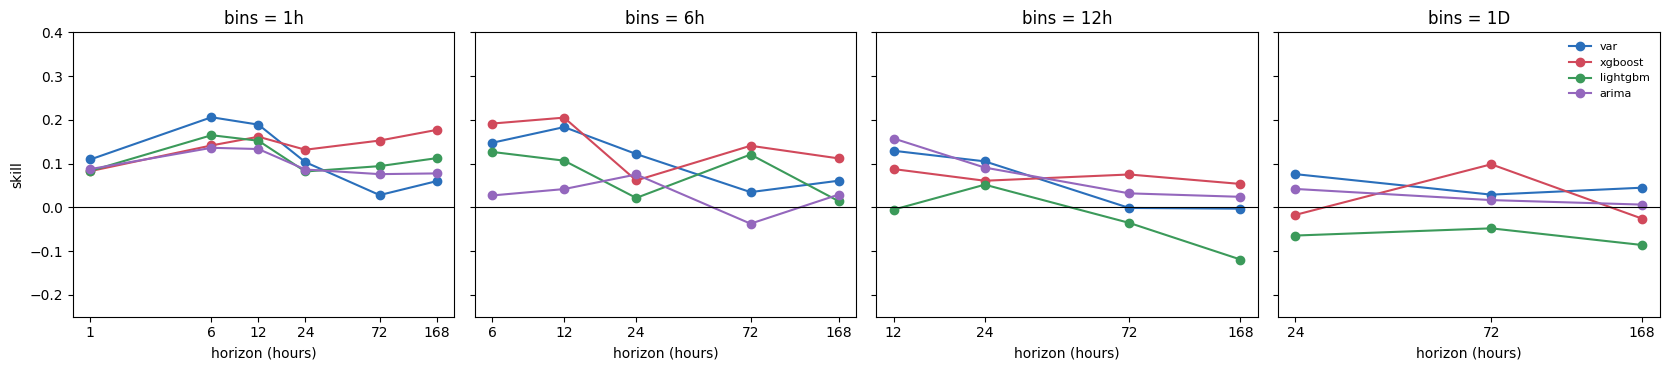

In [74]:
models = [m for m in ('var', 'xgboost', 'lightgbm', 'arima') if m in PRED]
SCORES = pd.concat([score(m) for m in models], ignore_index=True)
SCORES.to_csv(f'{OUT_DIR}/scores.csv', index=False)
pd.concat(PRED.values(), ignore_index=True).drop(columns='origin').to_csv(
    f'{OUT_DIR}/predictions.csv', index=False)

print('Skill vs "no change" (above 0 = better):')
display(SCORES.pivot_table(index=['freq', 'horizon_h'], columns='model', values='skill',
                           sort=False)[models].round(3))

colors = {'var': '#2a6fbb', 'xgboost': '#d1495b', 'lightgbm': '#3b9a5a', 'arima': '#9467bd'}
fig, axes = plt.subplots(1, len(DATA), figsize=(4.2 * len(DATA), 3.8), sharey=True, squeeze=False)
for ax, fq in zip(axes[0], DATA):
    g = SCORES[SCORES.freq == fq]
    for m in models:
        gm = g[g.model == m].sort_values('horizon_h')
        ax.plot(gm.horizon_h, gm.skill, marker='o', label=m, color=colors[m])
    hs = sorted(g.horizon_h.unique())
    ax.axhline(0, color='k', lw=0.8)
    ax.set_xscale('log'); ax.set_xticks(hs); ax.set_xticklabels(hs); ax.minorticks_off()
    ax.set_title(f'bins = {fq}'); ax.set_xlabel('horizon (hours)')
axes[0][0].set_ylabel('skill')
Y_LIM = (-0.25, 0.40)          # same limits in both notebooks (before and after exogenous)
axes[0][0].set_ylim(*Y_LIM)
axes[0][-1].legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/skill_by_horizon.png', dpi=140); plt.show()

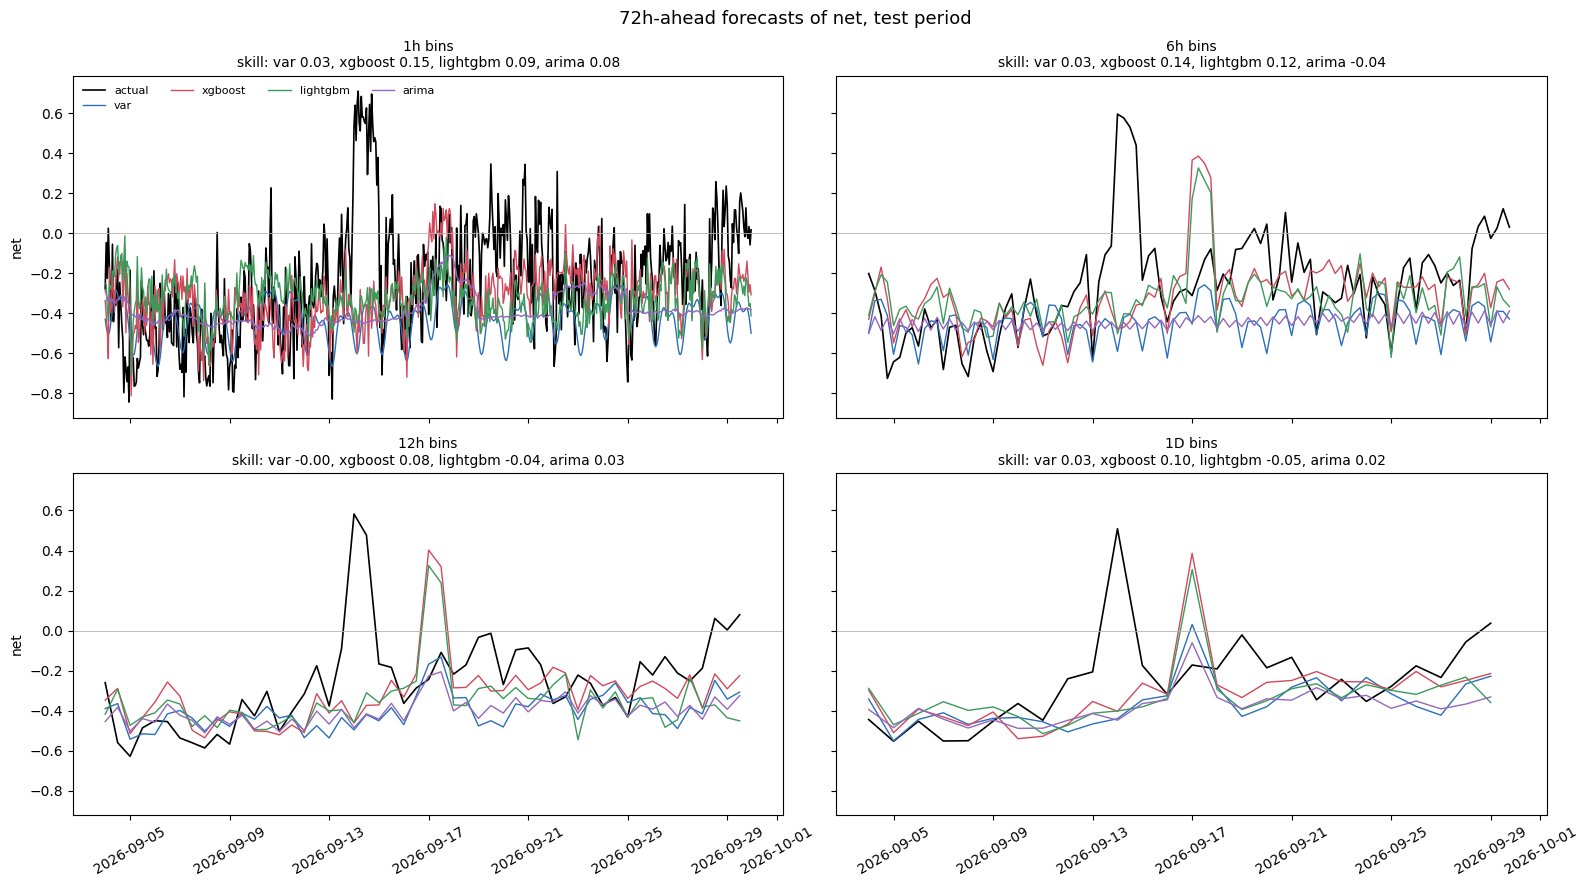

In [75]:
# 72h-ahead forecasts: the four bin sizes in a 2x2 grid
# top left = 1h, top right = 6h, bottom left = 12h, bottom right = 1D
h = 72
fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharex=True, sharey=True)
for ax, fq in zip(axes.ravel(), DATA):
    ref = PRED['persistence'].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
    if ref.empty:
        ax.set_title(f'{fq} bins: no {h}h horizon'); continue
    ax.plot(ref.origin_time + pd.Timedelta(hours=h), ref.y_true, color='k', lw=1.2, label='actual')
    for m in models:
        g = PRED[m].query('freq == @fq and horizon_h == @h').sort_values('origin_time')
        ax.plot(g.origin_time + pd.Timedelta(hours=h), g.y_pred, lw=1, label=m, color=colors[m])
    ax.axhline(0, color='0.7', lw=0.6)
    sk = SCORES.query('freq == @fq and horizon_h == @h').set_index('model').skill
    ax.set_title(f'{fq} bins\nskill: ' + ', '.join(f'{m} {sk[m]:.2f}' for m in models if m in sk),
                 fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel(TARGET)
for ax in axes[1]:
    ax.tick_params(axis='x', labelrotation=30)
for ax in axes.ravel()[len(DATA):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, ncol=4, fontsize=8, loc='upper left')
fig.suptitle(f'{h}h-ahead forecasts of {TARGET}, test period', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/forecast_all_bins.png', dpi=140, bbox_inches='tight'); plt.show()

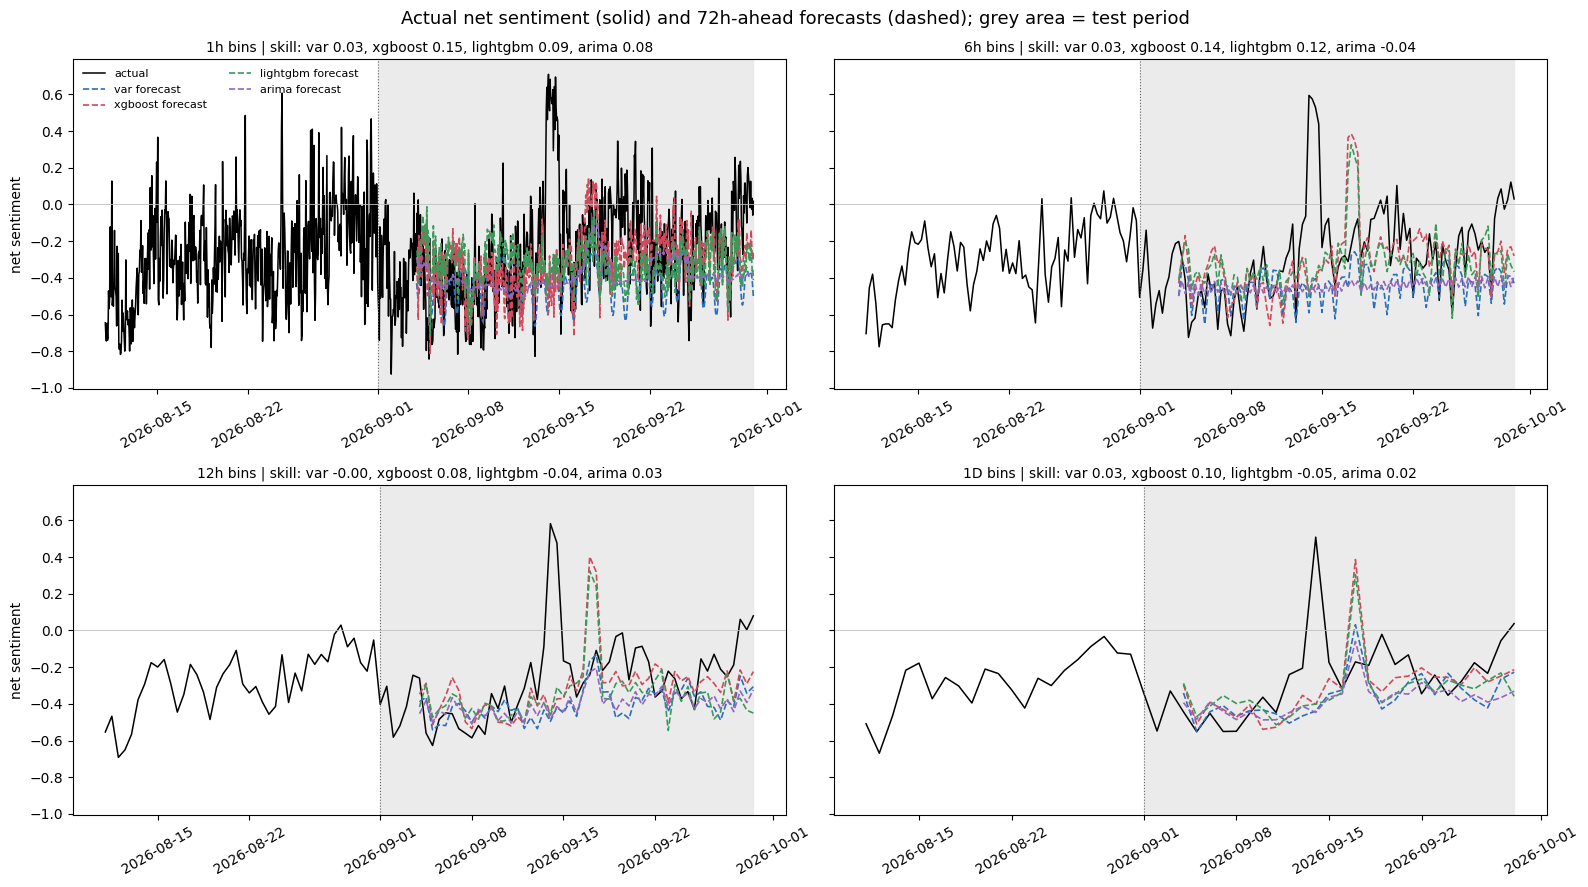

In [76]:
# ===== Forecast vs actual track, 2x2 grid =====
# Solid line   = actual net sentiment (part of the training period + the whole test period)
# Dashed lines = forecasts of each model, placed at the time they forecast (forecast time + horizon)
# Top left = 1h, top right = 6h, bottom left = 12h, bottom right = 1D
H_PLOT      = 72     # horizon to show (hours): 24, 72 or 168 exist for every bin size
DAYS_BEFORE = 21     # how many days of actual data before the test period to show

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)
for ax, fq in zip(axes.ravel(), DATA):
    D = DATA[fq]
    # --- actual track (solid)
    start = TEST_START_TS - pd.Timedelta(days=DAYS_BEFORE)
    actual = pd.Series(D['y'], index=D['times'])
    actual = actual[actual.index >= start]
    ax.plot(actual.index, actual.values, color='k', lw=1.1, label='actual')
    # --- forecasts (dashed)
    for m in models:
        g = PRED[m].query('freq == @fq and horizon_h == @H_PLOT').sort_values('origin_time')
        if g.empty:
            continue
        ax.plot(g.origin_time + pd.Timedelta(hours=H_PLOT), g.y_pred,
                ls='--', lw=1.2, color=colors[m], label=f'{m} forecast')
    # --- mark the test period
    ax.axvspan(TEST_START_TS, actual.index[-1], color='0.92', zorder=0)
    ax.axvline(TEST_START_TS, color='0.4', lw=0.8, ls=':')
    ax.axhline(0, color='0.75', lw=0.6)
    sk = SCORES.query('freq == @fq and horizon_h == @H_PLOT').set_index('model').skill
    ax.set_title(f'{fq} bins | skill: ' + ', '.join(f'{m} {sk[m]:.2f}' for m in models if m in sk),
                 fontsize=10)
    ax.tick_params(axis='x', labelrotation=30)
for ax in axes[:, 0]:
    ax.set_ylabel(f'{TARGET} sentiment')
for ax in axes.ravel()[len(DATA):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, ncol=2, fontsize=8, loc='upper left')
fig.suptitle(f'Actual net sentiment (solid) and {H_PLOT}h-ahead forecasts (dashed); '
             f'grey area = test period', fontsize=13)
fig.tight_layout()
fig.savefig(f'{OUT_DIR}/forecast_track_{H_PLOT}h.png', dpi=140, bbox_inches='tight')
plt.show()

In [77]:
# ===== Extra evaluation metrics for =====
#  MAE        average size of the error (same unit as the target)
#  RMSE       like MAE but punishes big misses more
#  bias       average error; > 0 = model forecasts too high on average
#  R2         1 - SSE/SST on the test period (1 = perfect, 0 = no better than the test mean,
#             can be negative)
#  corr       correlation between forecast and actual (pattern match, ignores level)
#  dir_acc    share of forecasts that get the DIRECTION of change right (up vs down)
#  skill      1 - MAE / MAE("no change")
rows = []
pers = PRED['persistence'][['freq', 'horizon_h', 'origin', 'y_pred']].rename(columns={'y_pred': 'y_now'})
for m in models:
    P = PRED[m].merge(pers, on=['freq', 'horizon_h', 'origin'])
    for (fq, h), g in P.groupby(['freq', 'horizon_h'], sort=False):
        e = g.y_pred - g.y_true
        sst = ((g.y_true - g.y_true.mean()) ** 2).sum()
        moved = (g.y_true - g.y_now) != 0
        rows.append(dict(
            freq=fq, horizon_h=h, model=m,
            MAE=e.abs().mean(), RMSE=np.sqrt((e ** 2).mean()), bias=e.mean(),
            R2=1 - (e ** 2).sum() / sst,
            corr=np.corrcoef(g.y_pred, g.y_true)[0, 1],
            dir_acc=(np.sign(g.y_pred - g.y_now) == np.sign(g.y_true - g.y_now))[moved].mean()))
METRICS = pd.DataFrame(rows).merge(SCORES[['freq', 'horizon_h', 'model', 'skill']],
                                   on=['freq', 'horizon_h', 'model'])
METRICS.to_csv(f'{OUT_DIR}/metrics.csv', index=False)
for col in ('MAE', 'RMSE', 'R2', 'dir_acc'):
    print(f'\n{col}')
    display(METRICS.pivot_table(index=['freq', 'horizon_h'], columns='model', values=col,
                                sort=False)[models].round(3))
print('\nAll metrics saved to', f'{OUT_DIR}/metrics.csv')


MAE


model             var  xgboost  lightgbm  arima
freq horizon_h                                 
1h   1          0.143    0.147     0.147  0.146
     6          0.176    0.190     0.185  0.191
     12         0.194    0.200     0.202  0.207
     24         0.224    0.217     0.229  0.228
     72         0.256    0.223     0.239  0.243
     168        0.283    0.248     0.267  0.278
6h   6          0.120    0.114     0.123  0.137
     12         0.141    0.138     0.155  0.166
     24         0.175    0.188     0.196  0.185
     72         0.215    0.191     0.196  0.231
     168        0.255    0.241     0.268  0.263
12h  12         0.111    0.117     0.129  0.108
     24         0.158    0.166     0.168  0.161
     72         0.192    0.177     0.198  0.185
     168        0.246    0.232     0.274  0.239
1D   24         0.145    0.159     0.167  0.150
     72         0.168    0.156     0.181  0.170
     168        0.216    0.232     0.246  0.225


RMSE


model             var  xgboost  lightgbm  arima
freq horizon_h                                 
1h   1          0.184    0.189     0.190  0.185
     6          0.229    0.243     0.244  0.244
     12         0.254    0.258     0.269  0.266
     24         0.298    0.287     0.296  0.295
     72         0.338    0.299     0.310  0.323
     168        0.365    0.333     0.340  0.358
6h   6          0.162    0.160     0.171  0.176
     12         0.201    0.195     0.214  0.219
     24         0.256    0.261     0.275  0.260
     72         0.303    0.276     0.274  0.308
     168        0.338    0.327     0.338  0.337
12h  12         0.162    0.173     0.187  0.164
     24         0.225    0.238     0.239  0.229
     72         0.274    0.261     0.278  0.269
     168        0.321    0.318     0.344  0.314
1D   24         0.204    0.229     0.239  0.210
     72         0.249    0.245     0.258  0.250
     168        0.292    0.316     0.329  0.300


R2


model             var  xgboost  lightgbm  arima
freq horizon_h                                 
1h   1          0.580    0.557     0.552  0.576
     6          0.349    0.264     0.257  0.260
     12         0.200    0.175     0.106  0.127
     24        -0.090   -0.009    -0.073 -0.065
     72        -0.388   -0.087    -0.172 -0.272
     168       -0.684   -0.397    -0.455 -0.618
6h   6          0.582    0.591     0.535  0.503
     12         0.363    0.398     0.274  0.240
     24        -0.024   -0.067    -0.182 -0.062
     72        -0.423   -0.179    -0.165 -0.467
     168       -0.866   -0.752    -0.874 -0.863
12h  12         0.504    0.434     0.337  0.495
     24         0.058   -0.048    -0.061  0.027
     72        -0.383   -0.249    -0.424 -0.332
     168       -1.060   -1.017    -1.356 -0.960
1D   24         0.130   -0.090    -0.194  0.082
     72        -0.283   -0.246    -0.380 -0.299
     168       -0.960   -1.292    -1.483 -1.060


dir_acc


model             var  xgboost  lightgbm  arima
freq horizon_h                                 
1h   1          0.658    0.665     0.666  0.632
     6          0.701    0.681     0.700  0.696
     12         0.740    0.725     0.725  0.683
     24         0.660    0.683     0.639  0.642
     72         0.615    0.633     0.609  0.622
     168        0.691    0.748     0.697  0.667
6h   6          0.678    0.687     0.696  0.600
     12         0.746    0.702     0.719  0.658
     24         0.580    0.634     0.598  0.554
     72         0.587    0.712     0.683  0.529
     168        0.693    0.716     0.591  0.602
12h  12         0.719    0.649     0.614  0.719
     24         0.607    0.571     0.661  0.571
     72         0.519    0.615     0.577  0.500
     168        0.682    0.591     0.568  0.659
1D   24         0.571    0.464     0.571  0.571
     72         0.615    0.692     0.615  0.577
     168        0.591    0.591     0.591  0.682


All metrics saved to results_onlysocial2/metrics.csv


  1h done
  6h done
 12h done
  1D done

MAE training vs test, per bin size (mean over horizons)


MAE_train                 MAE_test                 MAE_ratio           \
model   xgboost lightgbm    var  xgboost lightgbm    var   xgboost lightgbm   
freq                                                                          
1h        0.185    0.124  0.192    0.204    0.211  0.212     1.098    1.700   
6h        0.133    0.074  0.155    0.174    0.187  0.181     1.294    2.509   
12h       0.118    0.085  0.151    0.173    0.192  0.177     1.449    2.223   
1D        0.106    0.110  0.143    0.182    0.198  0.176     1.722    1.813   

              
model    var  
freq          
1h     1.099  
6h     1.159  
12h    1.158  
1D     1.243


Skill training vs test, per bin size (mean over horizons)


skill_train                 skill_test                 skill_gap  \
model     xgboost lightgbm    var    xgboost lightgbm    var   xgboost   
freq                                                                     
1h          0.179    0.446  0.149      0.141    0.115  0.116     0.037   
6h          0.252    0.584  0.134      0.142    0.078  0.110     0.110   
12h         0.260    0.464  0.063      0.069   -0.027  0.057     0.191   
1D          0.303    0.283  0.067      0.018   -0.066  0.050     0.285   

                       
model lightgbm    var  
freq                   
1h       0.331  0.033  
6h       0.506  0.025  
12h      0.491  0.005  
1D       0.349  0.017

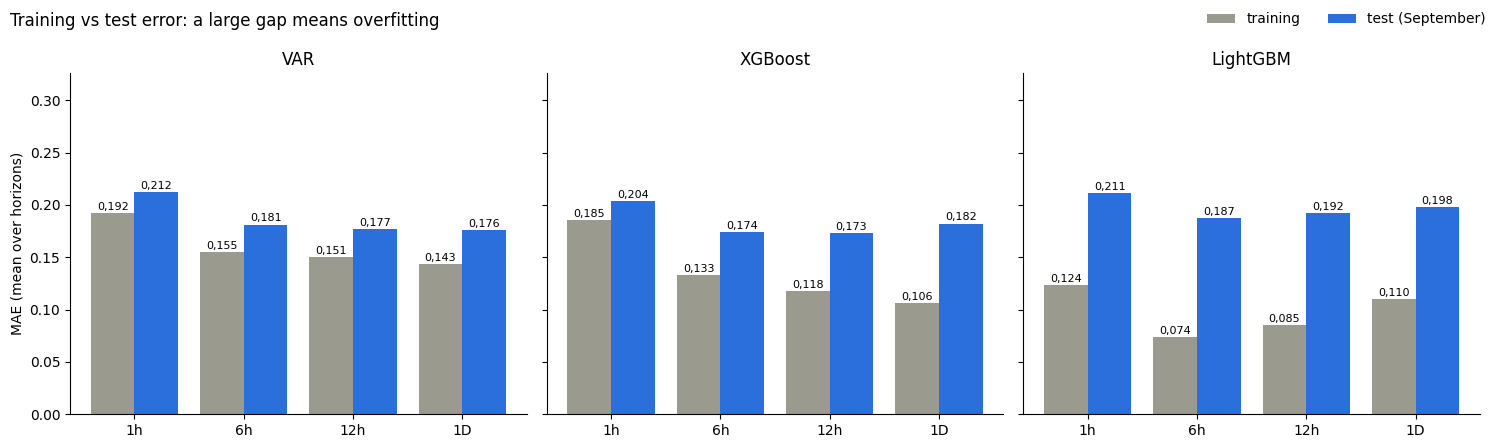

In [78]:
# ===== TRAINING vs TEST ERROR (overfitting check) =====
# Training error: each model is fitted on the data before the first test fold (until 31 Aug)
#                 and then predicts that SAME training data.
# Test error    : the walk-forward errors on September already computed (SCORES).
# A test error much larger than the training error = the model memorised the training data.
# ARIMA is left out: its in-sample multi-step forecasts are slow to compute and it has few parameters.

TT_ROWS = []

for fq, D in DATA.items():
    X, y, w, T = D['X'], D['y'], D['w'], D['T']
    _, _, train_end = D['folds'][0]                 # cutoff = start of the test period

    # ---- XGBoost and LightGBM: refit on the training period, predict the training period
    for name, maker in (('xgboost', make_xgb), ('lightgbm', make_lgb)):
        for s in D['steps']:
            tr = np.where(D['valid'] & (np.arange(T) + s < train_end))[0]
            if len(tr) < 50:
                continue
            m = maker()
            m.fit(X[tr], y[tr + s] - y[tr], sample_weight=w[tr + s])
            pred = y[tr] + m.predict(X[tr])
            TT_ROWS.append(dict(freq=fq, horizon_h=s * D['hours'], model=name,
                                MAE_train=np.mean(np.abs(pred - y[tr + s])),
                                MAE_pers_train=np.mean(np.abs(y[tr] - y[tr + s]))))

    # ---- VAR: fit on the training period, forecast from every training origin
    agg = D['agg']
    Z = np.column_stack([(agg['share_pos'] - agg['share_neg']).to_numpy(float),
                         agg['share_neu'].to_numpy(float),
                         np.log1p(agg['n'].to_numpy(float))])
    E = fourier_terms(D['times'], D['hours'])
    p, B, _ = fit_var(Z, E, train_end, P_MAX.get(D['hours'], 7))
    origins = np.arange(p, train_end - 1)
    yhat = var_target(forecast_var(Z, E, p, B, origins, max(D['steps'])))
    for s in D['steps']:
        ok = origins + s < train_end
        o = origins[ok]
        TT_ROWS.append(dict(freq=fq, horizon_h=s * D['hours'], model='var',
                            MAE_train=np.mean(np.abs(yhat[ok, s - 1] - y[o + s])),
                            MAE_pers_train=np.mean(np.abs(y[o] - y[o + s]))))
    print(f'{fq:>4} done')

TT = pd.DataFrame(TT_ROWS)
TT['skill_train'] = 1 - TT.MAE_train / TT.MAE_pers_train

test_scores = pd.concat([score(m) for m in ('var', 'xgboost', 'lightgbm') if m in PRED])
TT = TT.merge(test_scores[['freq', 'horizon_h', 'model', 'MAE', 'skill']]
                .rename(columns={'MAE': 'MAE_test', 'skill': 'skill_test'}),
              on=['freq', 'horizon_h', 'model'])
TT['MAE_ratio'] = TT.MAE_test / TT.MAE_train      # > 1 = larger error on unseen data
TT['skill_gap'] = TT.skill_train - TT.skill_test  # > 0 = model does better on data it has seen
TT.to_csv(f'{OUT_DIR}/train_vs_test_error.csv', index=False)

TT_MODELS = ['var', 'xgboost', 'lightgbm']
print('\nMAE training vs test, per bin size (mean over horizons)')
display(TT.pivot_table(index='freq', columns='model', values=['MAE_train', 'MAE_test', 'MAE_ratio'],
                       sort=False).reindex(['1h', '6h', '12h', '1D']).round(3))
print('\nSkill training vs test, per bin size (mean over horizons)')
display(TT.pivot_table(index='freq', columns='model', values=['skill_train', 'skill_test', 'skill_gap'],
                       sort=False).reindex(['1h', '6h', '12h', '1D']).round(3))

# ---- chart: MAE training vs test per bin size, one panel per model
BINS = [b for b in ['1h', '6h', '12h', '1D'] if b in set(TT.freq)]
fig, axes = plt.subplots(1, len(TT_MODELS), figsize=(15, 4.5), sharey=True)
for ax, mdl in zip(axes, TT_MODELS):
    g = TT[TT.model == mdl].groupby('freq')[['MAE_train', 'MAE_test']].mean().reindex(BINS)
    xx = np.arange(len(BINS))
    ax.bar(xx - 0.2, g.MAE_train, 0.4, label='training', color='#9a9a8e')
    ax.bar(xx + 0.2, g.MAE_test, 0.4, label='test (September)', color='#2a6fdb')
    for i, (a, b) in enumerate(zip(g.MAE_train, g.MAE_test)):
        ax.text(i - 0.2, a + 0.003, f'{a:.3f}'.replace('.', ','), ha='center', fontsize=8)
        ax.text(i + 0.2, b + 0.003, f'{b:.3f}'.replace('.', ','), ha='center', fontsize=8)
    ax.set_xticks(xx, BINS)
    ax.set_title(mdl.upper() if mdl == 'var' else mdl.capitalize().replace('gbm', 'GBM').replace('Xgboost', 'XGBoost'))
    ax.spines[['top', 'right']].set_visible(False)
axes[0].set_ylabel('MAE (mean over horizons)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, frameon=False, ncol=2, loc='upper right')
axes[0].set_ylim(0, TT[['MAE_train', 'MAE_test']].max().max() * 1.15)
fig.suptitle('Training vs test error: a large gap means overfitting', x=0.01, ha='left', fontsize=12)
fig.tight_layout()
fig.savefig(f'{OUT_DIR}/train_vs_test_error.png', dpi=200, bbox_inches='tight')
plt.show()

Method: mean |SHAP| | horizon 24h | share_% = share of total importance

Share of importance by feature group (%)


group          net history  calendar  exogenous
freq model                                     
1h   xgboost          92.7       1.2        6.1
     lightgbm         75.0       8.5       16.4
6h   xgboost          89.9       2.3        7.7
     lightgbm         69.6       7.5       22.9
12h  xgboost          89.2       1.2        9.6
     lightgbm         71.3       5.2       23.5
1D   xgboost          66.0       2.6       31.4
     lightgbm         63.1       3.3       33.6

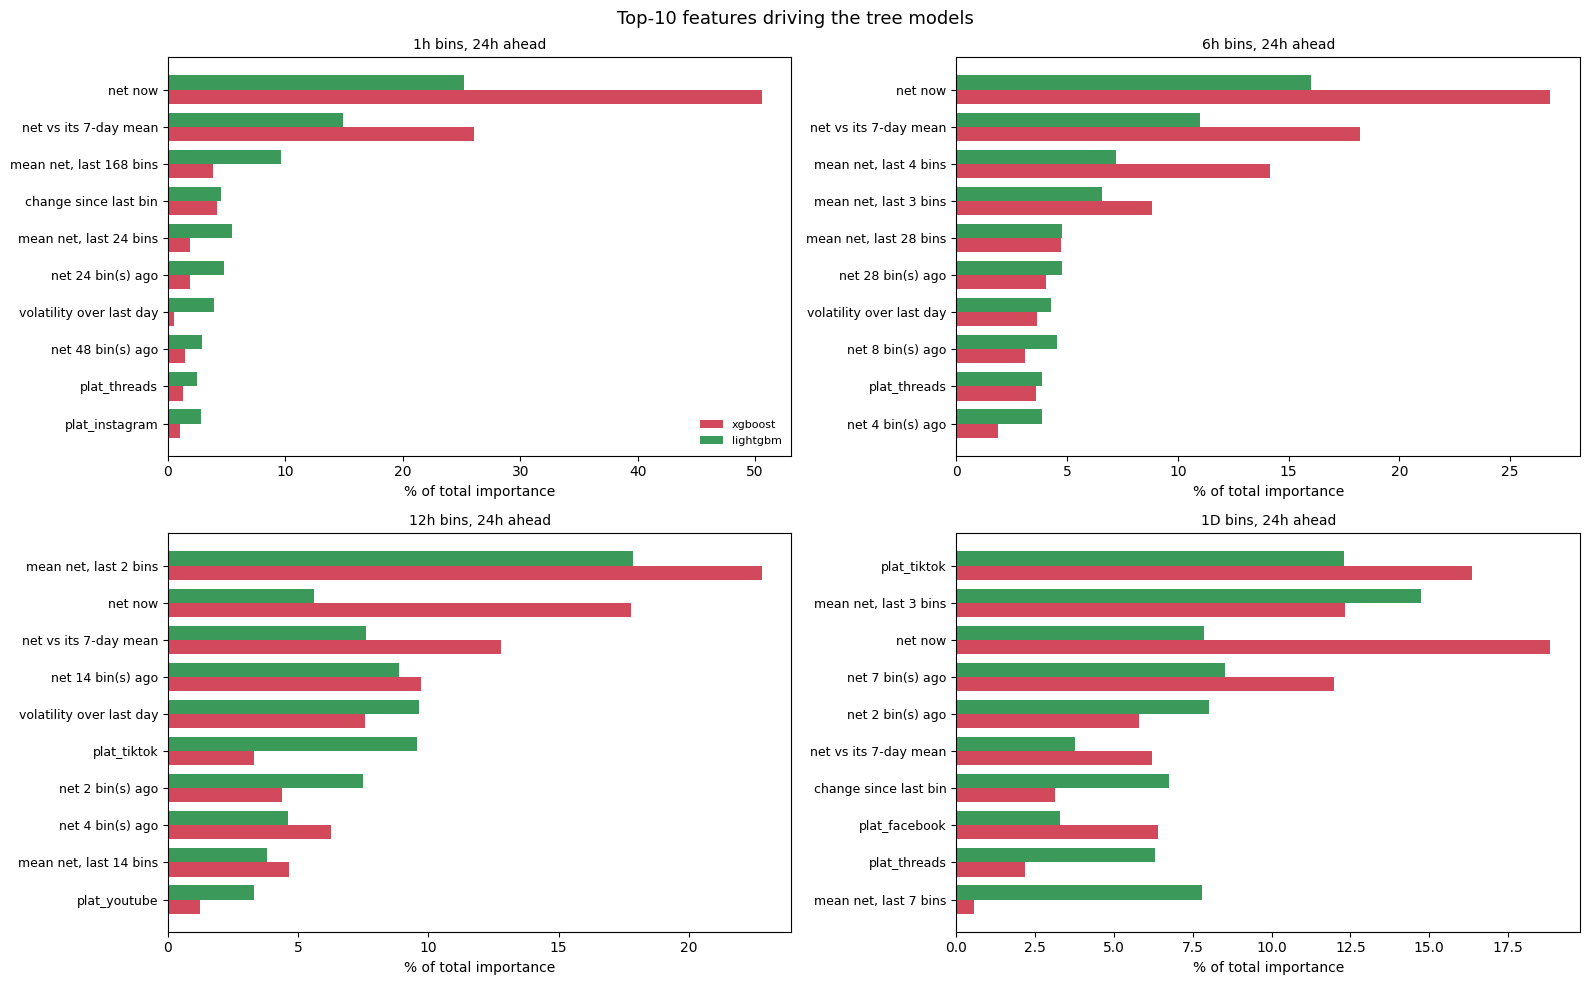

In [79]:
# ===== 13. Which features drive XGBoost / LightGBM? =====
# Uses the models fitted in cells 6-7 (last test fold) and explains their forecasts
# on the test period with SHAP values: how much each feature moves the forecast, on average.
H_EXPLAIN = 24          # horizon (hours) to explain; must exist for the bin sizes
colors = {'var': '#2a6fbb', 'xgboost': '#d1495b', 'lightgbm': '#3b9a5a', 'arima': '#e08a2c'}
FEATURE_INFO = {
    'y_lag0': 'net now', 'y_diff1': 'change since last bin', 'y_dev_week': 'net vs its 7-day mean',
    'y_std_recent': 'volatility over last day', 'logn': 'post volume now',
    'logn_surge': 'volume surge vs 7-day mean', 'logn_diff1': 'change in volume',
    'share_neu': 'neutral share', 'share_pos': 'positive share', 'share_neg': 'negative share',
    'hour_sin': 'hour of day (sin)', 'hour_cos': 'hour of day (cos)',
    'dow_sin': 'day of week (sin)', 'dow_cos': 'day of week (cos)', 'is_empty': 'empty bin flag'}
def describe(f):
    if f in FEATURE_INFO: return FEATURE_INFO[f]
    if f.startswith('y_lag'): return f'net {f[5:]} bin(s) ago'
    if f.startswith('y_mean'): return f'mean net, last {f[6:]} bins'
    if f.startswith('y_dev_ewm'): return f'net vs EWMA (span {f[9:]})'     # <-- new
    if f.startswith('y_ewm'): return f'EWMA of net (span {f[5:]})'          # <-- new
    return f
def feature_group(f):
    if f.startswith(('news_', 'plat_')) or f in ('is_weekend', 'is_active_hours', 'is_holiday'):
        return 'exogenous'
    if f.startswith('y_'): return f'{TARGET} history'
    if f.startswith('logn') or f == 'is_empty': return 'post volume'
    if f.startswith('share'): return 'other shares'
    return 'calendar'
def importance(name, m, X, y_delta):
    """mean |SHAP| (native in xgboost / lightgbm); falls back to permutation importance."""
    try:
        if name == 'xgboost':
            c = m.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)
        else:
            c = m.predict(X, pred_contrib=True)
        return np.abs(np.asarray(c)[:, :-1]).mean(0), 'mean |SHAP|'
    except Exception:
        from sklearn.inspection import permutation_importance
        r = permutation_importance(m, X, y_delta, n_repeats=5, random_state=0,
                                   scoring='neg_mean_absolute_error')
        return np.clip(r.importances_mean, 0, None), 'permutation importance'

IMP_ROWS = []
for fq, D in DATA.items():
    s = H_EXPLAIN // D['hours']
    if H_EXPLAIN % D['hours']:
        continue
    idx = np.where((D['times'] >= TEST_START_TS) & D['valid'] & (np.arange(D['T']) + s < D['T']))[0]
    Xt, yd = D['X'][idx], D['y'][idx + s] - D['y'][idx]
    for name, store in (('xgboost', XGB_MODELS), ('lightgbm', LGB_MODELS)):
        keys = [k for k in store if k[0] == fq and k[1] == H_EXPLAIN]
        if not keys:
            continue
        m = store[max(keys, key=lambda k: k[2])]     # model from the last fold
        imp, how = importance(name, m, Xt, yd)
        for f, v in zip(D['feature_names'], imp):
            IMP_ROWS.append(dict(freq=fq, model=name, feature=f, description=describe(f),
                                 group=feature_group(f), importance=v, method=how))
IMP = pd.DataFrame(IMP_ROWS)
IMP['share_%'] = 100 * IMP.importance / IMP.groupby(['freq', 'model']).importance.transform('sum')
IMP.to_csv(f'{OUT_DIR}/feature_importance_trees.csv', index=False)
print(f'Method: {IMP.method.iloc[0]} | horizon {H_EXPLAIN}h | share_% = share of total importance\n')

# importance by feature group (comparable with the VAR breakdown in cell 14)
TREE_GROUP_SHARE = IMP.pivot_table(index=['freq', 'model'], columns='group', values='share_%',
                                   aggfunc='sum', sort=False).round(1)
print('Share of importance by feature group (%)')
display(TREE_GROUP_SHARE)

# top-10 features per bin size: 2x2 grid, xgboost and lightgbm side by side
freqs_imp = list(dict.fromkeys(IMP.freq))
fig, axes = plt.subplots(2, 2, figsize=(16, 10), squeeze=False)
for ax, fq in zip(axes.ravel(), freqs_imp):
    g = IMP[IMP.freq == fq]
    top = g.groupby('description')['share_%'].mean().nlargest(10).index[::-1]
    yy = np.arange(len(top))
    for j, name in enumerate(('xgboost', 'lightgbm')):
        v = g[g.model == name].set_index('description')['share_%'].reindex(top).fillna(0)
        ax.barh(yy + (j - 0.5) * 0.38, v, height=0.38, color=colors[name], label=name)
    ax.set_yticks(yy); ax.set_yticklabels(top, fontsize=9)
    ax.set_xlabel('% of total importance'); ax.set_title(f'{fq} bins, {H_EXPLAIN}h ahead', fontsize=10)
for ax in axes.ravel()[len(freqs_imp):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8, loc='lower right')
fig.suptitle('Top-10 features driving the tree models', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/feature_importance_trees.png', dpi=140, bbox_inches='tight'); plt.show()

FEVD: where the uncertainty of the NET forecast comes from (% , rows sum to 100)


p  post volume  neutral share  net sentiment
freq horizon_h                                              
1h   24         6         13.7            1.2           85.1
     168        6         13.4            1.2           85.4
6h   24         1          4.2            5.7           90.1
     168        1          5.9            5.2           88.9
12h  24         1          7.3            6.1           86.5
     168        1          7.9            7.3           84.8
1D   24         1          3.6            4.5           91.9
     168        1          5.4            5.0           89.6


Granger causality (p < 0.05 = the cause helps predict the effect)


freq                               1h      6h    12h     1D
cause         effect                                       
neutral share net sentiment   0.00995   0.804  0.643  0.865
              post volume      0.0283   0.681   0.51  0.814
post volume   net sentiment   0.00807   0.156      1  0.843
              neutral share     0.544   0.608      1   0.75
net sentiment neutral share    0.0502   0.188  0.525  0.149
              post volume    2.82e-09  0.0313  0.273  0.173


Half-life of a shock to net sentiment (hours until its effect is halved):
{'1h': 1, '6h': 24, '12h': 48, '1D': 96}


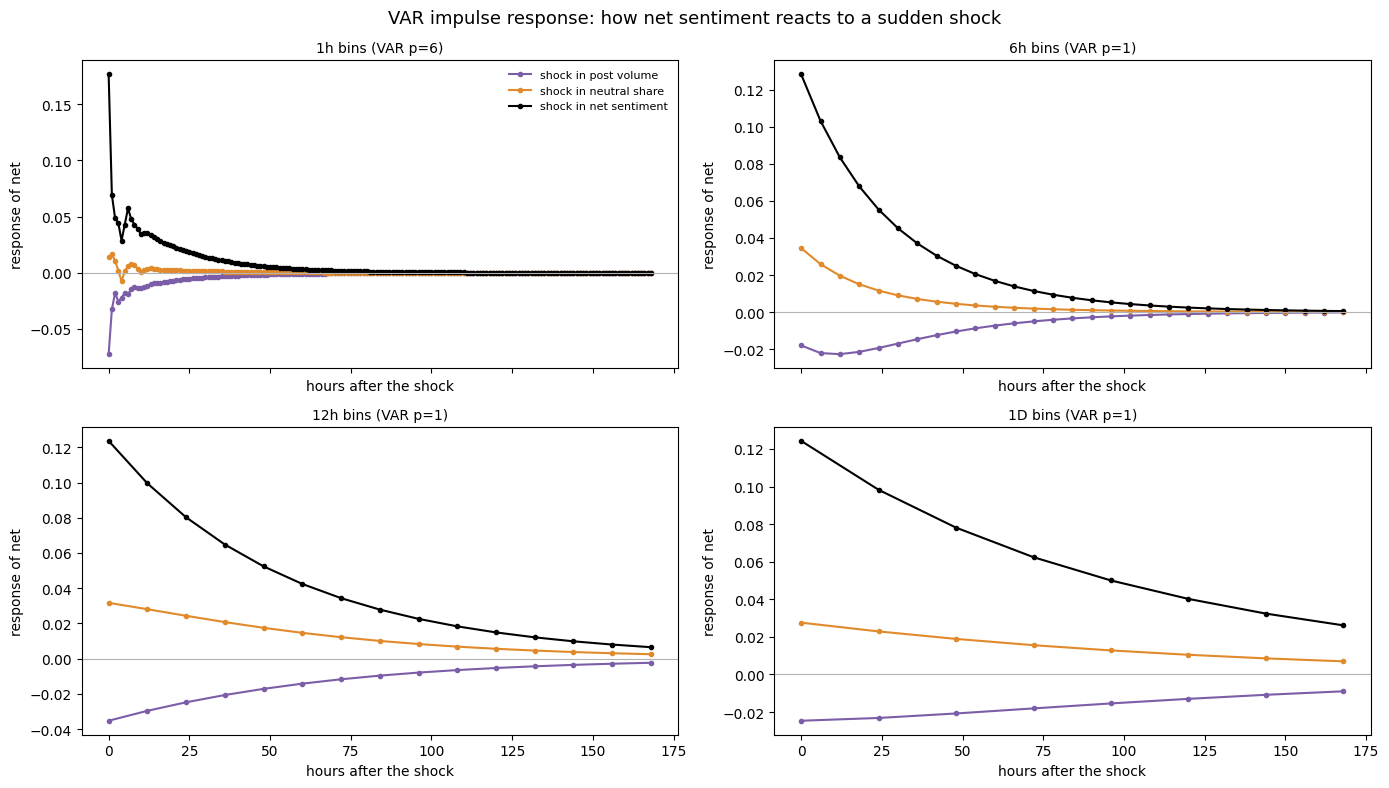


Comparison (different methods, compare the ranking rather than the exact %):
    1h | VAR FEVD: own net 85%, volume 14%, neutral 1%  | trees (xgb): net history 93%, volume 0%, shares 0%, calendar 1%
    6h | VAR FEVD: own net 90%, volume 4%, neutral 6%  | trees (xgb): net history 90%, volume 0%, shares 0%, calendar 2%
   12h | VAR FEVD: own net 86%, volume 7%, neutral 6%  | trees (xgb): net history 89%, volume 0%, shares 0%, calendar 1%
    1D | VAR FEVD: own net 92%, volume 4%, neutral 4%  | trees (xgb): net history 66%, volume 0%, shares 0%, calendar 3%


In [80]:
# ===== 14. What drives VAR? (FEVD, Granger causality, impulse response) =====
# VAR has no "features"; its equivalents are:
#  FEVD     % of the uncertainty in the net forecast that comes from shocks to each variable
#  Granger  does variable X help predict net (beyond net's own past)? p < 0.05 = yes
#  IRF      how net responds over time when one variable gets a sudden 1-SD shock
# Shocks are separated with a Cholesky ordering: volume first, then neutral share, then net
# (net may react within the same bin to volume and neutral; not the other way round).
# The daily/weekly rhythm (sine/cosine terms) is a fixed pattern and not part of these numbers.
from scipy import stats

VAR_ORDER = ['logn', 'share_neu', 'net']
NAMES = {'logn': 'post volume', 'share_neu': 'neutral share', 'net': 'net sentiment'}
H_LIST = [24, 168]
IRF_DAYS = 7

def ma_coefs(A, n):
    k = A[0].shape[0]; Phi = [np.eye(k)]
    for s in range(1, n):
        Phi.append(sum(A[i] @ Phi[s - 1 - i] for i in range(min(s, len(A)))))
    return Phi

FEVD_ROWS, GRANGER_ROWS, IRF = [], [], {}
for fq, D in DATA.items():
    hours, times = D['hours'], D['times']
    T0 = int(np.searchsorted(times, TEST_START_TS))
    Z = D['agg'][VAR_VARS].to_numpy(float); E = fourier_terms(times, hours)
    p, Bv, _ = fit_var(Z, E, T0, P_MAX.get(hours, 7))
    k, ne = Z.shape[1], E.shape[1]; off = 1 + ne
    rows = np.arange(p, T0)
    Xu = var_design(Z, E, p, rows); R = Z[rows] - Xu @ Bv
    Sigma = R.T @ R / len(rows)
    A = [Bv[off + L * k: off + (L + 1) * k, :].T for L in range(p)]
    o = [VAR_VARS.index(v) for v in VAR_ORDER]
    A_o = [a[np.ix_(o, o)] for a in A]
    P = np.linalg.cholesky(Sigma[np.ix_(o, o)])
    n_steps = max(IRF_DAYS * 24 // hours, max(H_LIST) // hours) + 1
    theta = [Ph @ P for Ph in ma_coefs(A_o, n_steps)]          # orthogonalised responses
    i_net = VAR_ORDER.index('net')
    # FEVD of net
    for h in H_LIST:
        H = h // hours
        if h % hours or H < 1: continue
        contrib = np.array([sum(theta[s][i_net, j] ** 2 for s in range(H)) for j in range(k)])
        FEVD_ROWS.append(dict(freq=fq, horizon_h=h, p=p,
                              **{NAMES[v]: 100 * contrib[j] / contrib.sum() for j, v in enumerate(VAR_ORDER)}))
    # Granger causality: every ordered pair
    for c in VAR_VARS:
        ic = VAR_VARS.index(c)
        ssr_u = ((Z[rows, ic] - Xu @ np.linalg.lstsq(Xu, Z[rows, ic], rcond=None)[0]) ** 2).sum()
        for g_ in VAR_VARS:
            if g_ == c: continue
            ig = VAR_VARS.index(g_)
            drop = [off + L * k + ig for L in range(p)]
            Xr = np.delete(Xu, drop, axis=1)
            ssr_r = ((Z[rows, ic] - Xr @ np.linalg.lstsq(Xr, Z[rows, ic], rcond=None)[0]) ** 2).sum()
            df2 = len(rows) - Xu.shape[1]
            F = ((ssr_r - ssr_u) / p) / (ssr_u / df2)
            GRANGER_ROWS.append(dict(freq=fq, cause=NAMES[g_], effect=NAMES[c], F=F,
                                     p_value=stats.f.sf(F, p, df2)))
    # IRF of net, and half-life of a shock to net itself
    own = np.array([theta[s][i_net, i_net] for s in range(n_steps)])
    below = np.where(np.abs(own) <= 0.5 * abs(own[0]))[0]
    IRF[fq] = dict(hours=hours, theta=theta, p=p,
                   half_life_h=(int(below[0] * hours) if len(below) else None))

FEVD = pd.DataFrame(FEVD_ROWS).round(1)
GRANGER = pd.DataFrame(GRANGER_ROWS)
GRANGER['significant'] = np.where(GRANGER.p_value < 0.05, 'yes', 'no')
FEVD.to_csv(f'{OUT_DIR}/var_fevd.csv', index=False); GRANGER.to_csv(f'{OUT_DIR}/var_granger.csv', index=False)

print('FEVD: where the uncertainty of the NET forecast comes from (% , rows sum to 100)')
display(FEVD.set_index(['freq', 'horizon_h']))
print('\nGranger causality (p < 0.05 = the cause helps predict the effect)')
display(GRANGER.pivot_table(index=['cause', 'effect'], columns='freq', values='p_value',
                            sort=False)[list(DATA)].map(lambda v: f'{v:.3g}'))
print('\nHalf-life of a shock to net sentiment (hours until its effect is halved):')
print({fq: v['half_life_h'] for fq, v in IRF.items()})

# IRF plot: response of net to a 1-SD shock in each variable, 2x2 grid
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True, squeeze=False)
shock_col = {'logn': '#7b5ea7', 'share_neu': '#e08a2c', 'net': 'k'}
for ax, (fq, v) in zip(axes.ravel(), IRF.items()):
    n = IRF_DAYS * 24 // v['hours'] + 1
    x = np.arange(n) * v['hours']
    for j, var in enumerate(VAR_ORDER):
        ax.plot(x, [v['theta'][s][i_net, j] for s in range(n)], marker='o', ms=3,
                color=shock_col[var], label=f'shock in {NAMES[var]}')
    ax.axhline(0, color='0.7', lw=0.8)
    ax.set_title(f'{fq} bins (VAR p={v["p"]})', fontsize=10)
    ax.set_xlabel('hours after the shock'); ax.set_ylabel('response of net')
for ax in axes.ravel()[len(IRF):]:
    ax.set_visible(False)
axes[0, 0].legend(frameon=False, fontsize=8)
fig.suptitle('VAR impulse response: how net sentiment reacts to a sudden shock', fontsize=13)
fig.tight_layout(); fig.savefig(f'{OUT_DIR}/var_impulse_response.png', dpi=140, bbox_inches='tight'); plt.show()

# side-by-side summary with the tree models (if cell 13 was run)
if 'TREE_GROUP_SHARE' in globals():
    print('\nComparison (different methods, compare the ranking rather than the exact %):')
    for fq in DATA:
        f24 = FEVD[(FEVD.freq == fq) & (FEVD.horizon_h == 24)]
        if f24.empty or fq not in TREE_GROUP_SHARE.index.get_level_values(0): continue
        tv = TREE_GROUP_SHARE.loc[fq]
        print(f'  {fq:>4} | VAR FEVD: own net {f24["net sentiment"].iloc[0]:.0f}%, '
              f'volume {f24["post volume"].iloc[0]:.0f}%, neutral {f24["neutral share"].iloc[0]:.0f}%'
              f'  | trees (xgb): net history {tv.loc["xgboost"].get(f"{TARGET} history", 0):.0f}%, '
              f'volume {tv.loc["xgboost"].get("post volume", 0):.0f}%, '
              f'shares {tv.loc["xgboost"].get("other shares", 0):.0f}%, '
              f'calendar {tv.loc["xgboost"].get("calendar", 0):.0f}%')

In [81]:
# ===== Effect of exogenous features on XGBoost and LightGBM =====
before = pd.read_csv('results/scores.csv')          # previous run (without exogenous)
after  = pd.read_csv(f'{OUT_DIR}/scores.csv')       # this run (with exogenous)

cmp = (before[['freq', 'horizon_h', 'model', 'skill']]
       .merge(after[['freq', 'horizon_h', 'model', 'skill']],
              on=['freq', 'horizon_h', 'model'], suffixes=('_before', '_after')))
cmp = cmp[cmp.model.isin(['xgboost', 'lightgbm'])]
cmp['change'] = cmp.skill_after - cmp.skill_before

display(cmp.pivot_table(index=['freq', 'horizon_h'], columns='model',
                        values=['skill_before', 'skill_after', 'change'], sort=False).round(3))
print('\nMean change in skill:')
print(cmp.groupby('model').change.mean().round(3).to_string())

skill_before          skill_after           change         
model               xgboost lightgbm     xgboost lightgbm xgboost lightgbm
freq horizon_h                                                            
1h   1                0.112    0.111       0.083    0.083  -0.029   -0.028
     6                0.245    0.248       0.142    0.165  -0.103   -0.083
     12               0.253    0.241       0.161    0.152  -0.092   -0.089
     24               0.171    0.156       0.132    0.082  -0.039   -0.074
     72               0.157    0.141       0.153    0.094  -0.004   -0.047
     168              0.254    0.239       0.177    0.113  -0.076   -0.127
6h   6                0.155    0.115       0.191    0.127   0.036    0.012
     12               0.242    0.203       0.205    0.107  -0.037   -0.096
     24               0.037   -0.045       0.062    0.021   0.025    0.066
     72               0.078    0.061       0.141    0.121   0.063    0.060
     168              0.304    0.282       0.112    0.014  -0.192   -0.268
12h  12               0.178    0.076       0.087   -0.005  -0.091   -0.081
     24              -0.024   -0.049       0.061    0.052   0.085    0.100
     72               0.020   -0.017       0.075   -0.035   0.055   -0.019
     168              0.289    0.261       0.053   -0.119  -0.235   -0.380
1D   24              -0.044   -0.111      -0.017   -0.064   0.027    0.046
     72              -0.070   -0.078       0.098   -0.048   0.169    0.030
     168              0.249    0.283      -0.026   -0.086  -0.275   -0.369


Mean change in skill:
model
lightgbm   -0.075
xgboost    -0.040


In [82]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

BASE_DIR = 'results'          # run without exogenous variables (all four models)
EXOG_DIR = 'results_exog'     # run with exogenous variables (XGBoost, LightGBM)

base = pd.read_csv(f'{BASE_DIR}/scores.csv')
exog = pd.read_csv(f'{EXOG_DIR}/scores.csv')

BIN_ORDER   = ['1h', '6h', '12h', '1D']
BIN_LABEL   = {'1h': '1 jam', '6h': '6 jam', '12h': '12 jam', '1D': '1 hari'}
MODEL_ORDER = ['arima', 'var', 'xgboost', 'lightgbm']
MODEL_LABEL = {'arima': 'ARIMA', 'var': 'VAR', 'xgboost': 'XGBoost', 'lightgbm': 'LightGBM'}
MODEL_COLOR = {'arima': '#2a6fdb', 'var': '#8ab4ec', 'xgboost': '#9a9a8e', 'lightgbm': '#cfcfc6'}

def fmt(v, sign=False):
    s = f'{v:+.3f}' if sign else f'{v:.3f}'
    return s.replace('.', ',').replace('-', '−')

def horizon_group(h):
    return '≤ 12 jam' if h <= 12 else f'{h} jam'
HZ_ORDER = ['≤ 12 jam', '24 jam', '72 jam', '168 jam']

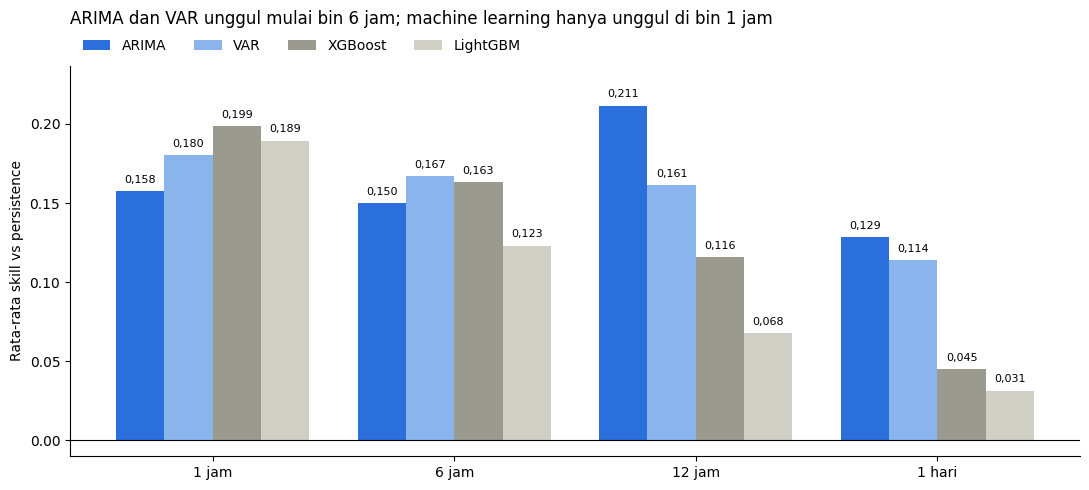

In [83]:
mean_bin = (base.groupby(['freq', 'model']).skill.mean()
                .unstack('model').reindex(BIN_ORDER)[MODEL_ORDER])

fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(BIN_ORDER))
w = 0.2
for i, m in enumerate(MODEL_ORDER):
    vals = mean_bin[m].to_numpy()
    bars = ax.bar(x + (i - 1.5) * w, vals, w, label=MODEL_LABEL[m], color=MODEL_COLOR[m])
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.004, fmt(v), ha='center', va='bottom', fontsize=8)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x, [BIN_LABEL[b] for b in BIN_ORDER])
ax.set_ylabel('Rata-rata skill vs persistence')
ax.set_ylim(min(0, mean_bin.min().min()) - 0.01, mean_bin.max().max() * 1.12)
ax.set_title('ARIMA dan VAR unggul mulai bin 6 jam; machine learning hanya unggul di bin 1 jam',
             loc='left', fontsize=12, pad=30)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False, ncol=4, loc='lower left', bbox_to_anchor=(0, 1.0))
fig.tight_layout()
fig.savefig(f'{BASE_DIR}/chart_skill_per_bin.png', dpi=200, bbox_inches='tight')
plt.show()

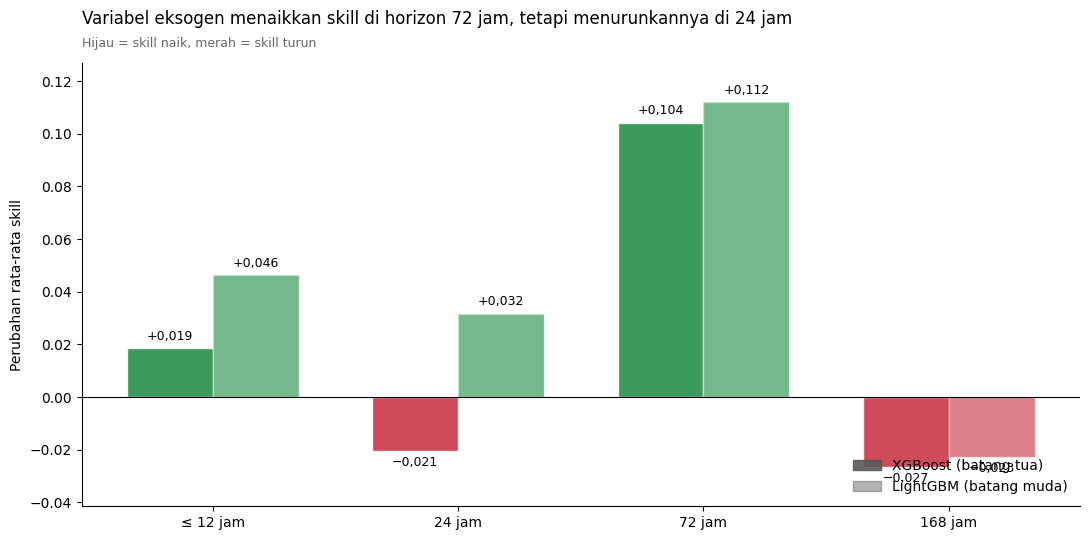

Skill sebelum dan sesudah variabel eksogen, per horizon


In [84]:
TREES = ['xgboost', 'lightgbm']
cmp = (base[base.model.isin(TREES)][['freq', 'horizon_h', 'model', 'skill']]
       .merge(exog[['freq', 'horizon_h', 'model', 'skill']],
              on=['freq', 'horizon_h', 'model'], suffixes=('_before', '_after')))
cmp['hz'] = cmp.horizon_h.map(horizon_group)
chg = (cmp.groupby(['hz', 'model'])[['skill_before', 'skill_after']].mean()
          .assign(change=lambda d: d.skill_after - d.skill_before)
          .reset_index())

fig, ax = plt.subplots(figsize=(11, 5.5))
x = np.arange(len(HZ_ORDER))
w = 0.35
all_vals = chg.change.to_numpy()
for i, m in enumerate(TREES):
    vals = chg[chg.model == m].set_index('hz').reindex(HZ_ORDER).change.to_numpy()
    colors = ['#3a9a5b' if v >= 0 else '#d1495b' for v in vals]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, color=colors, alpha=0.9 if i == 0 else 0.45,)
    bars = ax.bar(x + (i - 0.5) * w, vals, w, color=colors, alpha=0.9 if i == 0 else 0.45,
                  edgecolor='white')
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + (0.002 if v >= 0 else -0.002), fmt(v, sign=True),
                ha='center', va='bottom' if v >= 0 else 'top', fontsize=9)
ax.set_ylim(all_vals.min() - 0.015, all_vals.max() + 0.015)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x, HZ_ORDER)
ax.set_ylabel('Perubahan rata-rata skill')
ax.set_title('Variabel eksogen menaikkan skill di horizon 72 jam, tetapi menurunkannya di 24 jam',
             loc='left', fontsize=12, pad=28)
ax.text(0, 1.03, 'Hijau = skill naik, merah = skill turun',
        transform=ax.transAxes, fontsize=9, color='0.4', va='bottom')
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color='0.35', alpha=0.9, label='XGBoost (batang tua)'),
                   Patch(color='0.35', alpha=0.45, label='LightGBM (batang muda)')],
          frameon=False, loc='lower right')
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
fig.savefig(f'{EXOG_DIR}/chart_exog_change.png', dpi=200, bbox_inches='tight')
plt.show()

table_exog = chg.pivot(index='hz', columns='model', values=['skill_before', 'skill_after', 'change']).reindex(HZ_ORDER)
print('Skill sebelum dan sesudah variabel eksogen, per horizon')
display(table_exog.style.format('{:+.3f}'))